<img align="center" style="max-width: 900px; height: auto" src="../assets/banner.png">

<img align="right" style="max-width: 200px; height: auto" src="../assets/hsg_logo.png">

##  Lab 06 - Attention

Machine Learning, University of St.Gallen (HSG)

The lab environment of the **Machine Learning** course is powered by Jupyter Notebooks (https://jupyter.org), which allows one to perform a great deal of data analysis and statistical validation. In this lab, we will build our own GPT model, multihead self-attention method will be introduced.

<img align="center" style="max-width: 700px; height: auto" src="./assets/2021-Alan-D-Thompson-AI-Calendar-Timeline-Rev-2a.png" />

(Source: https://lifearchitect.ai/timeline/)

### Lab Objectives:

After today's lab, you should be able to:

> 1. Understand how **Multi-head Self Attention** works.
> 2. Build our own GPT model.  
> 3. Use GPT model to do text generation on Shakespeare's plays.

### Setup of the Lab Environment

Similar to the previous labs, we need to import a couple of Python libraries and set a random seed:

In [72]:
import math
from urllib.request import urlopen

import numpy as np
import matplotlib.pyplot as plt
import tqdm
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42)  # random seed for reproducibility

## 1. Dataset

For this lab, we use **tiny_shakespeare** as our dataset. This dataset has 40,000 lines of Shakespeare from a variety of Shakespeare's plays.

We first split the dataset into training and evaluation sets.

In [73]:
text = urlopen("https://raw.githubusercontent.com/HSG-AIML-Teaching/ML2025-Lab/main/lab_6/data/tiny_shakespeare.txt").read().decode("utf-8") 

In [74]:
print(text[:100])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You


We set the fraction of training set to **90%** of the original dataset, the rest **10%** is for evaluation:

In [75]:
total_raw_chars = len(text)
train_text = text[:int(total_raw_chars * 0.9)]  # 90% of the text for training
eval_text = text[int(total_raw_chars * 0.9):]   # 10% of the text for evaluation
print(f"Traing text length: {len(train_text)}")
print(f"Eval text length: {len(eval_text)}")

Traing text length: 1003853
Eval text length: 111540


But before we dive into the Dataset code, we first need to create some variables to record the information of our dataset.

In [ ]:
chars = sorted(set(text))  # all unique characters in the text, sorted so the char→id mapping is the same in every session
char_to_int = {c: i for i, c in enumerate(chars)} # mapping from char to int
int_to_char = {i: c for i, c in enumerate(chars)} # vice versa
vocab_size = len(chars)  # how many unique characters are there in the text?

In [77]:
vocab_size

65

Also set our training hyper-paramaters:

In [78]:
batch_size = 128 
num_epochs = 2  
learning_rate = 0.0001 
seq_length = 100 # length of each training window = the longest context the model can see

Now let's build our Dataset. The Dataset is actually very similar to the Dataset used in the LSTM lab session.

In [ ]:
class ShakespeareDataset(Dataset):
    def __init__(self, text, seq_length):
        self.text = text
        self.seq_length = seq_length  # length of each training window

    def __len__(self):
        return len(self.text) - self.seq_length

    def __getitem__(self, index):
        # take seq_length + 1 characters: the window plus the one character that follows it
        chunk = self.text[index:index + self.seq_length + 1]
        ids = torch.tensor([char_to_int[c] for c in chunk], dtype=torch.long)
        # input: the window
        # target: the same text shifted one to the right (the "next character" at every position)
        return ids[:-1], ids[1:]

Create the training and evaluation Datasets and their respective dataloaders:

In [80]:
train_dataset = ShakespeareDataset(train_text, seq_length)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

eval_dataset = ShakespeareDataset(eval_text, seq_length)
eval_dataloader = DataLoader(eval_dataset, batch_size=batch_size, shuffle=False, drop_last=True)

## 2. GPT (Generative Pre-trained Transformer)

<div>
<img align="center" style="max-height: 500px; width: auto" src="./assets/GPT1.png" />
</div>

#### 2.1. Self-Attention

For RNN models (e.g. LSTM), we assume that the current time step depends on the most recent time steps. But this can be limiting when dealing with long sequences or sequences with complex dependencies between elements.

On the other hand, the Transformer learns dependencies from the data using the self-attention method, which is why it has been successful in handling various kinds of data.

In short, self-attention allows the model to weight different parts of the input sequence, based on their importance for the current prediction. This can model the network better capture long-range dependencies and contextual information.

<div>
<img align="center" style="max-width: 600px; height: auto" src="./assets/attention_visualized.png" />
</div>

*Attention in machine translation (Bahdanau et al., 2015): each French output word (rows) attends to the English input words (columns). Note how "European Economic Area" is reordered. In **self**-attention, which GPT uses, a sequence attends to **itself**: rows and columns are the same sentence.*

To compute self-attention, the input sequence is first mapped to query, key, and value vectors. These vectors are then used to compute a weight (score) for each input element, based on how well it matches the query vector. The weighted sum of the value vectors is then used as the output of the self-attention layer. This way, the network can attend to different parts of the input sequence depending on the current query vector.

We divide the same element into three parts: query, key and value. In order to organize information.

Query: What this token is looking for.<br>
Key: What each token can be found by. So its label, used to match against queries.<br>
Value: What each token passes on if it is attended to.

We first need to calculate the attention score that determines the relevance between the keys and values. There are various methods to calculate it, in this lab session, we use Scaled Dot Product (Vaswani et al. 2017). The scaling factor prevents the dot product from getting too large, which can cause the softmax function to approach either 0 or 1, making the gradients too small or too large. 

$$score = attn(q,k) = \frac{q^T \cdot k}{\sqrt{|k|}}$$

Then we use scores to weight the value vectors.

$$attn\_output = score \cdot v$$

#### 2.2. Multi-head Self-Attention

<div>
<img align="center" style="max-width: 700px; height: auto" src="./assets/maxresdefault.jpeg" />
</div>

(Source: https://youtu.be/mMa2PmYJlCo)

The motivation of multi-head self-attention is to apply different attention layer/filter on the same input, and each layer/filter can attend to different aspects of the input data in parallel. This strategy allows the model to capture a richer set of relationships and dependencies. 

In [ ]:
class MultiheadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads

        self.query = nn.Linear(embed_dim, embed_dim)  # projects x to query vectors
        self.key = nn.Linear(embed_dim, embed_dim)    # projects x to key vectors
        self.value = nn.Linear(embed_dim, embed_dim)  # projects x to value vectors
        self.proj = nn.Linear(embed_dim, embed_dim)   # mixes the concatenated heads back together

        self.attn_dropout = nn.Dropout(dropout)
        self.proj_dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape  # batch size, sequence length, embedding dim

        # 1. project to Q, K, V and split the embedding into heads: (B, T, C) -> (B, heads, T, head_dim)
        # self.query(x): (B, T, 384)     project each token to its query
        # .view(...):    (B, T, 6, 64)   cut the 384 numbers into 6 heads of 64 (the -1 in the code calculates 64 on its own)
        # .transpose:    (B, 6, T, 64)   group by head, so each head has its own T x 64 query matrix

        q = self.query(x).view(B, T, self.num_heads, -1).transpose(1, 2)
        k = self.key(x).view(B, T, self.num_heads, -1).transpose(1, 2)
        v = self.value(x).view(B, T, self.num_heads, -1).transpose(1, 2)

        # 2. scaled dot-product scores: Q K^T / sqrt(d)  -> (B, heads, T, T)
        attn = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))

        # 3. causal mask: a token may only attend to itself and earlier tokens
        mask = torch.tril(torch.ones(T, T, device=x.device))
        attn = attn.masked_fill(mask == 0, float("-inf")) # −inf becomes 0 after softmax, so masked tokens get zero attention
        attn = F.softmax(attn, dim=-1) # normalises along the last dimension, the keys
        attn = self.attn_dropout(attn)

        # 4. weighted sum of the values  -> (B, heads, T, head_dim)
        y = attn @ v

        # 5. concatenate the heads again: (B, heads, T, head_dim) -> (B, T, C)
        y = y.transpose(1, 2).reshape(B, T, C)
        y = self.proj_dropout(self.proj(y))
        return y, attn  # we also return the attention weights for visualization

#### 2.3. Feed Forward Layer

In short, Feed Forward Layer is just a bunch of nonlinear layers.

In [82]:
class FeedForward(nn.Module):

    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

#### 2.4. Block

<div>
<img align="center" style="max-height: 500px; width: auto" src="./assets/GPT_ours.png" />
</div>

Inspired by https://github.com/karpathy/ng-video-lecture/blob/52201428ed7b46804849dea0b3ccf0de9df1a5c3/gpt.py, we slightly change the architecture, it can improve the final performance a little bit.

**Layer Normalization (LN)**: LN is used in deep learning to improve the training stability and convergence speed of neural networks. It addresses the problem of internal covariate shift, which occurs when the distribution of each layer's inputs changes during training due to the continuous update of the model's parameters. This can lead to slower convergence and make it challenging to train deep networks.

Let's say we have two inputs (batch size 2):

$\text{sample1} = [0.5, 0.7, 0.3, 0.6]$ <br>
$\text{sample2} = [0.2, 0.9, 0.6, 0.3]$

$\mu_{sample1} = (0.5+0.7+0.3+0.6)/4 = 0.525$ <br>
$\mu_{sample2} = (0.2+0.9+0.6+0.3)/4 = 0.5$

$\sigma_{sample1} = \sqrt{[((0.5 - 0.525)^2 + (0.7 - 0.525)^2 + (0.3 - 0.525)^2 + (0.6 - 0.525)^2)]/4}$ <br>
$\sigma_{sample2} = \sqrt{[((0.2 - 0.5)^2 + (0.9 - 0.5)^2 + (0.6 - 0.5)^2 + (0.3 - 0.5)^2)]/4}$

$\text{sample1}_{norm} = (\text{sample1}-\mu_{sample1}) / \sigma_{sample1}$ <br>
$\text{sample2}_{norm} = (\text{sample2}-\mu_{sample2}) / \sigma_{sample2}$

In [ ]:
class Block(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super().__init__()
        self.sa = MultiheadAttention(embed_dim, num_heads, dropout)   # attention: tokens exchange information (communication)
        self.ffwd = FeedForward(embed_dim, dropout)                   # feedforward: each token processes what it gathered (computation) 
                                                                      # proj only merges the heads linearly; the FeedForward is where each token doe nonlinear computation on what the attention collected.
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        attn_output, attn = self.sa(self.ln1(x))
        x = x + attn_output              # residual connection
        x = x + self.ffwd(self.ln2(x))   # residual connection
        #Residual connections let each layer add to the token's vector instead of overwriting it, so information and gradients can flow straight through all layers
        return x, attn

#### 2.5. Position Embedding

Consider these two sentences:<br>
1. "The girl saw the dog in the park." <br>
2. "In the park, the girl saw the dog."<br>

The position can make the meaining different.

<div>
<img align="center" style="max-height: 500px; width: auto" src="./assets/position_embed.png" />
</div>

(Source: https://towardsdatascience.com/concepts-about-positional-encoding-you-might-not-know-about-1f247f4e4e23)

#### 2.6. Wrap everything together to build GPT

In [ ]:
class GPTLanguageModel(nn.Module):
    def __init__(self, embed_dim, num_heads, n_layer, pos_len, dropout=0.2):
        super().__init__()
        # embed_dim: size of the token vectors
        # num_heads: number of attention heads per block
        # n_layer:   number of blocks stacked on top of each other
        # pos_len:   maximum sequence length the model can see (one position embedding per position)
        self.pos_len = pos_len

        self.token_embedding_table = nn.Embedding(vocab_size, embed_dim)  # one vector per character
        self.position_embedding_table = nn.Embedding(pos_len, embed_dim)  # one vector per position
        self.blocks = nn.Sequential(*[Block(embed_dim, num_heads, dropout) for _ in range(n_layer)]) # * unpacks the list to seperate args, e.g. *[1,2,3] -> 1,2,3
        self.ln_f = nn.LayerNorm(embed_dim)               # final layer norm
        self.lm_head = nn.Linear(embed_dim, vocab_size)   # scores (logits) for the next character

    def forward(self, input_seq, targets=None):
        B, T = input_seq.shape

        tok_emb = self.token_embedding_table(input_seq)                                    # (B,T,C), map the tokens to their embeddings
        pos_emb = self.position_embedding_table(torch.arange(T, device=input_seq.device))  # (T, C)
        x = tok_emb + pos_emb                                                              # broadcasts to (B, T, C)

        attn_list = []  # keep the attention weights of every block for visualization
        for block in self.blocks:
            x, attn = block(x)
            attn_list.append(attn)

        logits = self.lm_head(self.ln_f(x))  # (B, T, vocab_size): at every position (T), a score for each possible next character

        loss = None
        if targets is not None:
            # flatten batch and time: every position is one "predict the next character" example so we treat it as a classification and use cross-entropy
            loss = F.cross_entropy(logits.view(B * T, -1), targets.view(B * T)) # (12800, 65) vs (12800,)
            # cross-entropy does softmax inside the method

        return logits, loss, attn_list

    @torch.no_grad()
    def generate(self, prompt, char_to_int, int_to_char, device, max_new_tokens=300, return_attention=False):
        # prompt: the starting text (a string)
        # max_new_tokens: how many characters to generate at most
        generated_text = prompt
        idx = torch.tensor([char_to_int[c] for c in prompt], dtype=torch.long).unsqueeze(0).to(device)  # encode prompt to ids (character by character), add batch dim with unsqueeze -> (1, T)

        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.pos_len:]           # the model can only see the last pos_len characters, that is its context window
            logits, _, attn_list = self(idx_cond)       # calling the model runs forward(), we have no targets so we ignore the loss

            probs = F.softmax(logits[:, -1, :], dim=-1)  # (1, 65): turned into probabilities for the next charac that add up to 1 across the 65 characs
            next_id = torch.multinomial(probs, num_samples=1)  # sample one character, (1, 1)

            generated_text += int_to_char[next_id.item()] #.item() to go from (1,1) to just one int
            idx = torch.cat((idx, next_id), dim=1)       # append and continue

        if return_attention:
            return generated_text, attn_list
        return generated_text

## 3. Training

#### 3.1. Training setup

We first define some hyperparameters.

In [85]:
# define the hyperparameters for GPT
embed_dim = 384
num_heads = 6
n_layer = 6
pos_len = seq_length      # one position embedding per position in the window
device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: mps


Now we define our GPT model.

In [86]:
gpt_model = GPTLanguageModel(embed_dim=embed_dim, num_heads=num_heads, n_layer=n_layer, pos_len=pos_len).to(device)

Sometimes it's useful to see how big our model is.

In [87]:
# count the number of trainable parameters
trainable_params = sum(p.numel() for p in gpt_model.parameters() if p.requires_grad)
print("Trainable parameters:", trainable_params)

Trainable parameters: 10735937


<img align="center" style="max-width: 700px; height: auto" src="./assets/model_size_history.png">

source: [Link](https://vega.github.io/editor/#/url/vega-lite/N4IgrgzgpgTgtlALgQxALlFOAjKATAeQAdEBLAewDsJ1REALLKdEAM1IDcl7SZEBPKKQDm9RCAC+EgDQgAxlXbDaIDqSgB3FQsplKYcpADqpPA3QAWAAxXZOvQcgAJIaPFoAzDZkhkAD1IaDBAAG2RcEIAxKkQAZVIAL2Y0ACZbEDJEEKho3Xik9C8fbOEoSjwVYRhkPHVdABky4XM0a3SqmrrEABUeOQBrSigIIK9ZMIjcuMTkgEYADlkIfhxyEPy5sYzSLJyYjfQ0qXHkQRh0AG1QPGQUFUpkBBYblABaPCtsBdmAdisLWYATh+rGwgJqUFmHlYcisUCgyDk8wsN2YPjgyBg-RUAiIyRARHIpF0IFk7BC2QqaFYyBC0CWM3QsyOsjKClqlGUwQUIXI52CuPxlHIcGJtNJbHUISpIAAIiLkMTJLI8EhFSEcfw8SxhaKHhqyVKZfKMUqfOQiIidvxtFRamQqCoOLSwHMllBsnIHZQWNBPYg+TYfsrVC7klYAHQpHwQejIbUCrVCkVig2Sj3GhVm2QBtZkIiXOhJnUp-US9gZlixfgQRBYZVFhMgXWp8tGlgAJSgrFgbLR0kb+LrcEJ1TTFelLAACmBsCFSHJbhRKAACF79wcsACOYGQuh2S64bcraBAU8xjyQsBoZL5GPcIAjsw3GWLp5bZcNJ7lWZ9EgAurIfiak2w6juKX6TqeM5zguS5UGutz9iANqJk2O57pkh7MLI-iBCorB3rcLBPshE4yue1QIHWMA3iAECLtkKh4L+lyzNIXg2Fx3FcYBr5NryyhSD4jAiGI6AAGw2O6-rLiofpQF6gZWMGaH4nAYAhGQx7SkEFw-qaPp8dgxIyiUZQVMc2y7NOF7UbAK4KGAugruQrArgAsvUK7LLWWAQCuDAwIYoiBaQTyyBopgtLMszeAOIAvKgwQPE8p5Ja8ACsIIpICeDYFYKQWKwEmZXgFjIB4HhQB4KQSXIKSQqweCZTYFghhiWIgfi85DBKcjzgWaCIDArqyISxLuDSdJQEsI3kP0UCysgsZsbYmX-j4bLkByXKgDyfLdSWeoQemUEGYqPrjFApTlOg+gUksfLuPpADil50fUe7CLupQSgQDCwBKABqgRyZtsgWlaAi2uUOxycEzohK6TIyYp3q+h66PKcGPhIyjaCRtGSxxgmm7vqWp3kSwJqXRK5l3WgD0hD4wFqSwYF8lT7bQbO86Lt6iF1iGqHkyAGH7igZBHpBFF2VetGSFIfEwMMaxHsEDG0sk+1rIdp6mVAeLlGU4gk-G+KG8bqoklZAAkDGMBiLBiIgRAQGgAD0ntcMIyARsIOz0LOEYUJ7jtYMgPs3cgrzznWPsWBG8xPhGABWECOiqtwrUgQTXDn7yfN8fwAsCoLgqqUIwnCCJIiiyDJFcIDVn5cBVgAcgAgh2ADC-0wH7lCJPBlAABQQAAlCwEpd2ADB8hP0+nh5mJqKuHnEhA-Q2rIXdEEQwWIvQM+yLTSqngDjDnLI3QrdiK-IEkPnq8Syi39UxJv652Bp+jnD4glAASUoANSAy5HIwB2LAUgyUQASk3tkWsVBAGyBgvzUeQt8RAkyikV4VhZj4PmN0GwhMrBkIlF2HsqtQH4i7iuDuUAwBjleF3fU5AfpQBXL3WkchNK3D5CuAAQrnPAK4wCElXMgFcU5grYHCKQeO-BPI7Q9K5dyXZiSERgHIJgJJZD1GJA-eBsgnCmBtiuMIZwggmLPPLGiQRrAf0ut-BQI555cLHpEeoBApyxGXrYkB1C+yORFEQDxK4vE+L8QEiU3RP7D05ELXOD44kJO-klaAiAfIzEiUlCaugp6nxAAAUR3JwbWLkRouKSWQBAkT6CGForE2QQTey0LCvUsecAimnjSTU4QySsk5OfmPV6QiWkgHiQM0JtZIlpDSCuAAqrEWUsSZCgFbsOKsHp3IEEHnuRI38tn1lkPsoeI9vRL2KXPBeMBrmniER6OAMQVyRExNkZRe4xFGGGJ87hYQup7wPkfOQJ8+ln1YqeUGEA5K33vrZRANFVyqwUMIYeGNnFfySeQX+-8NaBNAcjWFCE5BQJorA4piDhgBj6hCs8fM4KC3XCwHBFh8GEIISQ8hpCbCUO7O03RLBXplFgLSS5EC3IrktEi2AKLFIcIxRA4kK5pF+lYK8PkFyEjf18tsgxRiXZIvdl7T2eAQgRkRHACMWqzVEk9nFJ8swLCZQdS63BgIUhPndV4QEEozF4AsVY68xTKKXgcYcFImUsWJMGW48JdZIneN8f44pbSaG6NCe4xNUSU2TOmdiwZmSkDFILbGoZSARmePyUSQpkyylgAqdkKp6TanhU8Y05hvTCXBI6XUzxPT82tqLTnYZsLRnjKHTMhQcyx4LKsMs1Z6yEonPbvS85hyEijweS3b5sDuF8nApikAtzGn3O7UYCMK5L3CMpJnWaK4gFXqEcFDQsbZ4gvIMfYp58fTQrBlnKZCLTy9zjNUL0DlUWKvhoBst39cV-y9AAtNRLwGkvJTAuBCDFE0pQaGxlAsIEstPDgwEHKOXcrIRQ2QVDBX4nPLKmA8q0VKoQt8lcqtOhJOwMojEYLiQ4RAIYygxjXYmu9hoSTEZ40eJgDawens5AQHNZ7Q+5BdH4DfhAV4mIyADSgJ7ZA7B3YOsBJlQEntWqZVaikKNDqUgEDgB3LcHcJIdgsB4f15iyiWNOCG+lYb7KK1SBJLYcGkkyZzcmmJKHe2Zsi546Lqb6XhZHSgLJpbh0VuyeO6tOcCmIG7RKBtTbTaBSy-2hpTSiutMoHFrhlXuk1amVl4tOXcljImZl6d5BZ3zsXWsmeGyW41m2aeWIjxXQhAYUwsc3DGADBDWcg5w8t1XOa6exe3au58GDjAFc9Qr0TY0h6D9anv30t-cKj6cTgMgFA4pRaisY3wbxUhglwDUMktXGS6BUCsOyGpcgultj0FMqI0hVlZmyMEIo7ynlVh+X1arCKLhtYwC1GGCuFVfGeBDEsQiJj39wG1MYCuP29SpVgse0toThr6UBqDX54LIAO6ey7hKQLCsgizAki9iLYSIm5pi-S9NISEtJuicl2xqXsvdcLdlqteT8u1sK-W8pSMyvVIV41ztzSWB+tq-VzpA7u0-AjJlfpCu2tK861OhXM7slzsKgulZg2+nDdXSwLusou71CAR3EpA9tXbo2-PM9O6TB4Ffaq8oK4nBuVYGd0F4LbFXf-d92729EXIo4wq9FMGrotZmQh-FqCQAgLAd9yBf3KX0qB7S8vYPCMIWIyAIEUlyNcvh9RkAtGM3l+E6J41HtvaBAtbWPc2i8ARnwGAT2AA-KK0fyAaFUxbWiimO9WBqPGaWwwoqIH45yCMRA8BJ9Md51cwaWec-sf534-O42C6i1LyZYuOkS+F9Lq35a2vy7-1HUrVy2VxQAK27VmAjBsBKQAGpCpisNdKlsltdy1ddqt386s6MTdIlB0ACMkgD2sJ0usUsstHd5kXcBtl1NlRt6xoJYBdESBgoi8N1VtQ9JlNtz12DP0Ls08oUQAYU4UgNs9HkxQYBlEBoVpYV2AW8i9ZdS93ty9K9iUIFfsKUAcQAG88MAsCNME28O88FYdu8Ede9+8+xpwoFQFSAiAkF1EZtmEdp+BUoFwIBpAVxYhLQ+A9xhFyAFoXCZsNAVwABNPkfoSJfQ6eA1ETYpRnHzG-GxO-KibnSwaSYvB3F-RLN-FgboDsLuAPEpWUYRQI+PLuDuWUT7Y3L-JLe3QA9LEtEgmZG3EAseGtSaZrErTXFtGZNArtAJbI3IwPAooRIopwEosoo3LAxrXA+o63Ag23SdPAgXPrCgt3KgkbNuKsSbNRRhZhWkebGnZ7EAFgiVKgHdWecPLbAJc8EIUUGBVw16K9djDsI7PcB4ZPL9MFH9Pg96BAOiO+YQ+7BbJ7X4rLeQ-fFDKvFQjDf7KlHDYHJvHQ5lSHEjQECSH4V4WKOHYwvlGjAVAfFHepdHTHAKHHY+ATAnTEctEnQZQGcnS8Ww6nRbWiK9SibJIBIBCUIfI1N2UfT2STDQaTCACMNQQeL+f2OfRfKAZ0agT2KoBERADQEIiAcOTYi1M-C-EAGI6-ZnGxNnDnNBe-YLJxVI8tSozI0XTAgfLNBNDIvNBYtLFJO0xXJoloutYpdopA8rLo9tKrHo2LCY70prao-A2owgzxeY6Yk03rJ3frFYobFdGgtdEAIRHwwrapIgFcLuG4EgUeYPTdNgm5c4zglgKPV9O4iRFAVw9jVeHYaoN4ngiUdPEAb44YLPYxIRMIAYNOREbEJ-H+RDME80iE9DWvdQzQkHTnBEiHYWZEn4DwfBGHWYSjeHJHOjacZyQIegT2LsDQTEPANAA7QnctQ-egVVbhclBcbHVcTMvfABFcXoVWWMNYMRVdT6enEAMTHk9QeEPwawvkKAUOeEf821FiPhBAXQT2DzKwT1H4FILzQNWI7U0NA0oIFIdiY01xdIyXW080iozC7-IMpJf-CM4MlJW3F0tXN0xA5tZAirAMvXZrD-TNSY5rWXRojrcMmXUgqM8gxZWMj3eM9Y08AAaXIEaSGFXCGHlJCNzNYPW3YMLNOOBXOw+NPCWWoAkVgDUGgAqEhUMhYCviBnhX+NlHbWoGXHFQEDzzwDACQ1gxBLewHMJSHJ+yhLr1sTHPhNghkKwSh3mE5TRKjSXIRxXLxPG12U1RWxmDEW0XvElXcgDEJEEjggpHEL5FRWyR7FuGYS4QxHdg5LfI-NNV6n6AjAgEPjflgGkxFEMz4AXGyAdUjDihUk9iEUiBsCqhgvmHmDgqZ2sSQsSIjVaCat7NNOwp7SwNGpF04oaIIMdLYtGXIraKoq11oq6XoowON2YoIvtLHXYuIOmrSKWN4qXTjOoMEo1ItHIhXEkoVKBUOMirW2XEUpPQUo224JUt4L0svkBhviEOMViCgB3BCQQBeSgUerspLwcuQ0HOUOHLUJhKQUb3wy8t0KRPb0BHmAMPZSMKo2xL71xLMNPG2LmxusVNjzESIHoBrGSp8gTICmPJXCYEHjKx5Fki4CtPnlHl2IUXjnUFfKiNPEKu9hMlKv0EtTkAjH6BgE9l7mq2GBlJ01ICgteBSE9kaSIHIkxtP3Px6oQr6qJvZwSPDX80BEBBSNl0mp-3GMtMtu2rl2IsItmOdJV1aPV0bQ6Joq9LWvQL9MtK2rmqdr2rtrIOd2Ovd3gU9wTO91iFgK7l7iD2WxDzkoLLuR3TYWj00BXHuOEV03IFcI7AXDA2fKO3nlpUrLj1Aw+SxxvXTuvEA33mUtTwbK+JuyMuMSnDWC4XkTCEsM5F-1e37OhqcthpcpHIRtw3HLQUnNbzRqBHmDnOVpxuXJxORyJtmyoHnEWlVSzP30ZuyDAsK0CjjGyUXFXEzhCHZtqFYGkM0myWyApIwt0GCmmzUznH8nyoFvfJH1NS-KgB-N5FVgAvhHk2EDtVAtNk9lCyhBUmDEv3gq1P1tB2QsKCKhGrwqqN9vF3QbNIOpqIdIdp2uAI60WrdtK06J1zop9pwv9K6SmNwZIt2qIODu4tDtdxOv4rOrG1sSOPBvHjD1Tu7Q7DAAQBCDA0QFcOWjUDERKQjAAG549JoqA7ioBE9VZlEZH5GTAKRYEel86qBaQxEAApCMOsj65ur6w4n61slgRoB+2pcgK07IRNEaKwpBfunFKGj7WrZymveG+vWEpG7QlGxE6c9G+YCSdEqwecoKkwgm2hGxw87+VWQ+YYU2UeAKHjFceRAYV4NTS0P2PQQZWAYKA4zkhnK-XzRBo2oLHnCwCwNB7NG0qa8oia7Bsa9xwh1JXs+avLMA1XJa92j0lA7+bo-Xahv2gMuhjpp0oOx0kOmM9hiOgSrhmS44vh+SgRgJIRkRsRiRq9GR1wgAMk8jkF7myApG+VcOMYO1Mabt0rplPC+k5F+kEz+OMWBlgGwFCUoDTjAAKcELkM8cUK+0hLHv8cRq0NB2ntXD0IxrRMMMXJ7zxtMPicecSdJy4UtDmTrGoCxylRKU5HnFjBXC4BgGwA9kfRHH5h2A400jxf2w8NpHObXECBcewA8QpuCl0RGDfgAH4P7jFdaEH-MkGBr-NUK0hzauLGmsLmnrasGZX8KA6QzlXSLna+nXbKLBnqLPSKHvbfTxmQl-aCGZmmG5mWGFnw6Gw1iuHGEehaQez7qk6nr+GI83rG7PiLGDLfq3mqw8RFITzlhdBGBYVgTIbB6vGK8QW4bMNx64TkaMEQnsE4X8EImrAJIYnkW4mhVoILwKQtikBbr+gAoGBbgDyKTAoHHZEqBDAOkCXhAiWTzug-6zY6dP6xNTU5BoFoBYA-BQ5axT8IAwBZ9rKfZ1ANAQK7U31eQahZGM5hhvtTAABeKwDwLuDwWUDwfItqoRLuSIDwTKawTKLuIRXuNq+egEWYIRazEpXlliUgJdx1SA59w9iMP4ZkQ55Jpd5J2YQ5wUJdtUoVypkV2YappItABYKSdIC2tpuVqN3CxVjBk1oi+hx2kMsil210+ld0nV4ZttfVsZ8aiZ2hli1rQOs1k1+Z5YxZ61r3U8a8kgW8l9HwuAHOnu3RX6nh-M+lDg56hulPT1h5ps1uv66cTurJ2kPcLtvu3s0Eoez7Hx1Q2N8FiezyxNqc5NrqrvRFrExHFe1c+jq8ne28wAHAJmORQ2OpPYBABcAhXAZphV3GmxAQTX5uH25NNT5NeHH1KpQDqz5Bn3FLxAtHquX1fXXzxE3zkDnvmD3F30Y64G1vVM1OA9v31LFeC1img+letNlatvg9acQ5wemZQ+K-I96fjH6dIY9t1dQMoYNaI6NcmdI5mvQ6aI4umao7DtWLo40KWQ7gD1Wd4b49eq4I9cuz4O9esZXk00YhZeQHRV63wlk6BfBJHt8eU-coCchYnOCY098oXMxNxr0-xtXt6-647hXFeFjxXBKR-NgGyRKQ8legzJ5cn30Tbbc-Ex9mwEoEtWQGHbwH6E9jKFU2haVI0kSR00oFeD-oi8QBh7gGEB01e98-h9grgd6pFbA8GvmHTalZ60K-aflc-1g7y9YtmuQ7K9AIq81ew+WvIdq4I4YotMa5I7tp6ciXa7QaOrYatcjvOr92BgDw7kG+49sV4-dYE-G69asbbsdLk8jaULQ1Hr8c24hcnoZV25ntCbnrI2ZEO+XpO4M5PXqCF47g7n3K8P+9pRFEMACh7rES4D6GyEvNPKGB2Om1JrurKa-vc+9jUw012kFPd6gXdmkzkHC9gFMy6rVpWk3L8pSGwAsHkRSHmBBEynhE+DkDyg82wGwFYEyjz6gDT9BFYXJeqS9AjDEDgDTGS7iNZWx-8w8FNqy4J5y6VcNZJ8J7g-J5Vcp9a+Icw4orp+1ZWq9o7SoYa77Sa-Z6p7t3NZ58oNOptdoO4YerF67m6EOe6GEQ9Gmy+mwC5gDCgRbL3hG5YECKvUaF7mcmEWfV6wcmudiCvVlDKCexXFlCvRcBNlogQieJu6-6r5dy16L-rOHkQwAxEh2D-lekMbdlTsSlKXp9SE4CFYMd2SuuBhoh54WMheaZgr2BaKdXKo5Lbhr2byo0deGNPXgYR05HcQqhNJMt2TybzdME8YawuoDEQBgVwcYcoBoHJQ4sVwOqdMuyC4RQYC8x6H3kLU9i-1-6f5IBkBQUwgVhGEDVEmZhgrtQMeetEVp5jS7G1gswIKSA03b5Icp+8WUnrPz76odOmGHDVlhxAAwVAQoHWQDhzH56sJ+9XFpsR1NxmC1WszSjha2o589lmq-WUEAhPYlJugJSWIKL2To8dz+42K9OnU4wjAyg+dQARwBCLIArmz6MoJQFcJCUr02dAgEgmSHk0ABK4f-jwl-5F5+O7xO5hdAviWNr4U3DQjN12K1B5uwoUNrgJW4w1le63aEip3jZBN1O2vZNvYO06ZtjuKLHNiehUSqgQgrweRNpQzLvUTyHAkBEO16gZk8AvzWsAfQFZckvuxVUquVU5CVU3EimUmDRAapPggwnsYEPMFeBzkJIFgPBBYHCatR8EAAfSBBAd6+AWZBq0FyhcQDBQuIwe4IVaGCiu3TCnhYNNbldwCVXIZqtVcGEdwR0-Nnqq0YZhl9qHXPwV12X49dugsoV4N8ReTMF1+0QivEIg8hnFNmNyFYYJ3qHNlfid2ERAMApxkiuhEbfAWtyU79C1eqnBNuDhGFQ5PU+CTKAb2Cr6dQqZ4DATTSAQjBXQxJVcM2xHBcxpsJla+lgVsZE4ZOH3A4TyUtARdg+VhQUnIAj5Gio+QIewZ7HJAGYJI8wXRNaMUgpA5A1mX4OZh+C6Id8KIeYCiTSAF8JR54CLol1+GIUSMjfYLFGmBHoUBc3fPLoxS4S21MRdRWERz2aJD8BmZDT2i4J9KojieTFGfimNDKc8cR3PaMv4O65R1TwQCakVlCiEusAktYjyHeQjDXMjAtwTOKuC7DQBMQYKbhKbEMovU6RdBTAZEGfSvochbhOsJTR8xdwX+e-aRFOHUDVJXCoMWhC5Guav8LmMiFcdUD0a4A+AB2K9B5HoJDjqh9Ze5vUKeY-R5urzO7NMmoBhBj0gLbkdOFgDWE-61oCMD+JfieEFOvIwgSwDMSiAQg4haBDpQ0LED8QAAPlag2BHIB4b0HRFIFJtRRC9CJrMEygTDaBqLKZGTlXiAxYqSmWwrEClissaaq8Y-FwkfEQBnxy4fclzkwElJaw4UHMpEU+48k+S4tEIBoCgDYAQGhmYNnrGED8BPYhjQEHOUlYeBPYYYqptoJqZMgJIUHfHmkXjEbUCukIonrGM6bmF1M8IIPrYRpI8IHgbQ1cB4XnCXh3uvfbwQtUzEBJICPweYLAXTYIFR+DPEZnV3zH5cPBOBZrjMQH4UdYRnXXnlWPOoNiTirrC4iwCeRMZgBp4-7NKHIC3NGRf6ITN9BeZNCWSmqDVGVXhD9iUAwgQOHqNfFl5VuvQvkW5Wwzq81OwomFrPVNrY1OU1Aw3lMPxB3wip38eto2zvIts7OQcU8tW3kQmQiWemWYfAP1GC1v6EmKTIiF4n8TBJmERpIJDEkST2UkrWYLJPUHCsWcupSMShRdTcQQRr+bSYmI5onSe+ZHcwaV0CnwjKurKKAlYBckSQ3J2Ymrp5KZ4aTfJgZYsXMTLE6TZkFY-ERwxX6Jld2HYeoCUkCIRT1mKdN1gEiEpQJWJXhRGayzKDQBVwrhIBDNAzJXoOwK0DSEkKkRx5yAP1OiBeLMZXi0pk3OXiazwHlTq8lUogTVKFHeVYWwIcYUi0mHZt6MwUayrZVXBSpcADkVgMFFY7LRh4xLDEFpG-jgD-kVQVfKuGPKGBkCZOSAFwilR4hWJXbVUK52iIVM-horHQTzmdQxiYO6kzBl3y0mXSWu+DNMXPxIZas3peHakl5OZ6bUix-fWydiOYaL8+KSzThqv3qCxBugNIxOnmUpG0j4ZOyA+PHnUz0BVYf2FcPI0MbMJbobhMFKKDwDBxDxKU6XkJxpmicwqQNDpCINYyrgx4vLCIgDPpk9DGZQEgYYEyhZa96p5AjmQixwnSi6B9QKgIMkfJ8BXgNEVjiDT5C7xJpvvIgB5ykwmRa0rAdOP0GHa3BQeLcpUk+Sj51R-goY7aSl3iIKTwOcUeCcdKaYJiWeVs0EVCIBkldoRt06ngiKdnVcXZ2BMeOtUtmFiMRXsrEaWN9lAzQpBI6sUJigB2t6x4c2So2O9xb8d+B-cmbEJACBEXiB5G-lOPqAABLhCMmSRSGBXCwRWMLuF36cgKArhBjFAgGDx4jMrAIYL9Qpmp5YgGlGAFpXwDmNkBAGWQmgLAyIhMBZcnActzfF1zQWqvMxMgmIW7FVY2QKUkKkBzQSWAkQXgHMmyb9A8mg8hJPgG4Tm9+WU9FuT5WRIY10SzUzuUbxlGvRqgmOXQCIiWE6jy0DdecMoo4HyhwGLkLsNgLEEFVjUpqLSsuB85T5-OI7efEpnMzzBPhZVCwsIGaqWjN8jQPhJQAxpbyNSBs8MSABel7zBqKk1vmpOtnS4vUflWAsyDREmCLZp4c3JkrgKW5r5dsjyP1xDk3TvZt8+6aeAkiPSXJag0pPTxzGM8UR7smhp4N+ltd9qkYQqA4IBkhSl+IMnrjDOG4jizwV6UGGsAyGeQYBKCcmQyPzn1CUBLC-4u8kzScKXx9lHhcPQqkNyBRgw5ucMNbn4gNp6JAwsQi5m4Tph+MogKYD7Low1wV4AWeIlhRJJpEh-KMsosXBaxVQthWFFSy4SZVEA2VPWVNL968kpMSmaTBpG8USlRZvWRTHLSVL1BqRwMZqsGOvBjtplrwOQBwEPgcpoldfOJftKZC48zZ2Xc+adNPm5K0lXgjLB-KIZ2TrBw-WxE4I8n4c2lX01np0sZUlj5+vgv2TR354rMQFazHdGpQAS0QdgyCp5SoifrILToEvAJNguDjSInk+CvOmUOQV-wvCsoGymBgQCEKVos3dcbol0CuFQMSMsgF4VgFgB14ecpAdeIyl3imhzbPwNkmt7qYwkTjAFtsrKm8KY2-I6qYKKGF1TNFIAaSfgjnJYS9FbU73HYTmxDSeaFEuQAdhdWlBxpaYcQdNMhX8k04NfOTLalCVKk0hyMBADJNwCarV2UcKtYHHIA1qiVsS+SXYnS4myzaR0gZaYIeleAslxSnyRCKpVTUvUvwDwLzhcmwNL5MI5jm+lCQwBwkYbAKVUozEsqIC9SuAgkqaXuSWlH0rlSwDSC85juZ041vbJvkCrgpeI3+cMv-lTgE5ucBYaIk9JPj2JTrCOWApiHjLb1iiKwumREpQB6AU4yINUEoAJAVwhjB-nsjBQSNDkaiVeDojACOrGFzq55q6tpnF5n1Wy8NgGt2X1ywWBypuTt2OURqo1VgCUUvSlH6K6BZEpcNrN2K3rqg0AV4KYuUW0T6JgGHNRCu4lzS+JAk21EtJEliSO4q7SJr8C2kxL4GO8-qsbPQD2DyVqkyMnkuMFJju1fKrpYP1XUBIvU0BOApOvZU7rOVeY9pd9KmYlLP5563EUKoCGBzEy-uHIqMqilFkeOiyp1WlJWVND0B7CyDPnnLlcjsNAEvZXhpDWHLCN4atvJK2xpokvAcanmSwCAQjhgoXAMRNREaRiIpUXAvADwJ2B8DaggcbJJsogR1g-IqWjeOUp35JRFhgmDjV924kMQ6guiWoOlSqpwBw4XbPsDVT0z1VwgSpO5aQE9ixBCoEkVPvMEyhSQ2gKkVCnJJA6kqIOPEI+bl25VnyLpZPK6XbMqVmbHZJGddf8FekPzkRhmgJC6hyUNZPZIAeCWtqZU+yF+P8oZQHNBnAT1AwUezRs2jmnhJG9y0DLAj1FULUpNjDNfeP+KsaX1pUhQgzL4UbcgtBG9RURrC02AyNuiq5V3Lwn0IzEYqHRH0Do13rGNzGsRB5FUTTZtE04mjXpl2JUS8cNE4DXRJfVVauJs0gaDxsWnCSVpnsKcKRsiZVQm1Emw2dNuZA8R5NGFRTUdvOnHz6VqY87fyo21srml70gzc-Mn6C6T1Yuv6d-J4pXrbtPXIRKQGDmhyVwBO9wvlJPhiqhuDmvjs5qQ3UzZeRcluP637H5aIaCuWuThrB3BqJFLMsNWzLRqSsyNDw8jbE1O5AbLwUUaANKjEpMBHIYQHltIUwQM0TIDW-+Po334hyWx7GUmdfGuqzZdiXvUIn2J4B1gvQoK-YeCuq1SZatfYWPZX3OEl7aE7WuqgZi62qZSAvW-rX6I8BSRyV8EnnZuuJUtqmJD+XBBSrb5DqT5CHOlcWLU3MqaeNgnbUiPH77bX5x29+aeuXVc8u1lmsKVw1iBx0nAkQw3WLyjnRThKzxMFH4QIDMlewCQPZjIigAAByWABfvnHpqwAWoygOy2Zr7Z2M2dKcFeg7jTKqhpuqmfpQt2+s6Z3Qx3UGqqku7Q1Ry0LR7th2czdO1y-EDwkgB0bgodYYkK8HiDopxUSSO1kWwCiv8oEiWnXWLM8i30rCBpNwm-GyCvBe4e-D-jnBMYcSDRpqSvbolKqtbaEGIYQIJPsAQMvA8wSzDBU2m4IPAEYXkHqK71Y9ElD+JyXNo75Kahd820fXyqsET7WVU+3Dnttl1uCCx8+3lYvrM3L6YOq+v+eFJ32Ryz+4ygughFiDCgNA0G1cKnOqCsBt4-AcumIgSGZ1L+DCd+Cej-11C0pN4zKWht80g7A1KvcHRAeC1Q7oDoTSVmm3h3wHEd0wgGhiH3Bpq74fgGtnAGUQgJ+ZgsBFaxxcA0QOEZQO3jdykZmEmDhemnfyW40LS+NjOjhGJJZ2YS4om0ybal1bXSaZtKShTSPs760rB9IurplOrPUS6NDzg1pbPsGN6G-JIxpXVdpV03baO-83uN0F7ivAy0yirXWHNfWgLIpTY2ULEBCGuFugSyPY8qu9zZA-AWdaoFwD8ITZ9w83BxpEDlQABDk2OfreT-dWJwoLOgAGeEA3xwxgAB-maq4WIJnNMA5zzx-hxsoXKANW79dWA6DJhvt0gH-NuG1XhDu24xH3dcRmwGmwiaBUEdlGvCbLUoBDABZrLXqWqLmxnNJCpASPd6H3IH89+38NStAGEAH1lFANEuZmmWgoB+pDAMoYpGYQ0JskxNXYrgcVIF6J5tRgUhGGP4xByAcKhfB0AeOSC5ANfT4fEY52Y8ujPejLlhP72pLhjc+xQ-IbF1j67ptPSXduul2uzPplphXaZou1fyljrDFYyKtX5Pa4Z++8XvCb4Jua0N6y4Qd5q4U1zMT3jQCYFqiOQ7Ne0OmA+m3wRokFg0W07l2H5kjMyctQMCt9gsrKIpUSUEUyeRD4Z7C2ipRg+PIkHcToVKp3QGqfFIL48ctKFrXVv-KAdt5XO6Q8Fg8Bya+dcYgYwoeTGqaVD6rNQ2bi22NK9NTpp+S-NmNPyTNYxpff9OMPXb-Zqxsw-sfFXG7JeNQn7RngBasKLwEGfbLbtkL+qwjoBiI87qgmu6oDBJ05USbTPolLlSR8k9MPoQ0g5k99XUYMlpDCA+QQcVjgTtVBGwsmHodQO5EkpgqFTU8-kg2b5Cqn1TbZqgIZnJYmZfziAUBAaY0FGmARh6ztebJHOC6xzBh0Xe6fF32T750+3Mdoe8nHqTtiu7pcru9NbnfTiZQAN3ArwIwF3FiBTh-TH6l7UGbG4ubftKGv6CEe4V+bYzAWnEwmbxNJnYjL5lSHAZoHJH8Q5i45I4TBRMFyjhix4J1ACi67I46RmRJiDeWDIGaX0HADcG4S8JNIkAeU3Wdp3zTeNCmfjUzpZ3pnmQHRnsySr7OOIO1Q55-ALt0NWmwR1F209UvtPm5PULk9HluudlaHFzCht06ucMPrmuKJh69edSES7HhL4vGBV3BuN3HkADx1wnBr4QBRDEUUAYKQFcIJ5aI2SIRM5EWhXNwT6cqE-QCzmwmYArhJ4zauAtvIPjXxxDf-uPOoD-iHm886idEF+qsNN5rE07vAMPnIDIW58-uqDDnLJRvu43mpR0C1glFxW3qFwnS2ZbCmC18uWWawESmysFZz3lWaxDwWJBAfAyVpgjAh9TR4fSPtLUlY-BY+sYCCgVGjE-BJJh7YEHVBahRcEQzfdNjBQkj8SewZfE6+wqr6IAa+nR3ed0cUkzamqfR-nWRcisUWbTE59TVOcRGaGZ9jFozTyvmOxXzN5Y5Y5xcCGJlUjmEC8k4Dj5vxire+xzWJcQFm6ADjQmS9GZ2WrWwDzMza-ibIFqWHh+vOKJmeN6c2LLPN2MHzeqMIWZpSFs0bCpbO0RJO-QYOP9aVLKZdMNe-CztNxvGmUKySom8OYtNLmybMVim+Prvkj9UrtN9K-LpYvUXFjgqzc8KvZvFIuOFh4caJcmsBHJLt46S5btCOOUpbd59ax5VZny2drVgb3emewlkn41YVUUEOwi70KxE-58tFTjCTsK1w6mRQS5GSYPk0myEu6xBfTKZ63rua+s4KUbMBh1TwGtbOQGXnHKlSfdgRF5x1MhAs71tyTf8LbWFBedch6KwOsW3C7lDlFmixpros02GLvtyK5lZsnZX2LlrNfX6fMPvqSr4y6O42SCOobLd6wkaDZUFiTQPxqsciXbvLsxmo2BA+MxteiMqXtrp4SVjDm90tSKN+d-Gloj5C6ID65bACzrsESrwD438O+6NAFklsHGXcVB65Y7vuX6djRheD5eVrtGrAYmyQ4RdnsQcqoZp-o87dHMqa17xZUyKvgCguAQg6ZdjDQoPjPRWLlNz2+3gjBVQXJWglK7tp9ty7d7-trKx6eZsr7g7Vmu7eugpFn2BbJu8SyLceZ-amhyDh+8ql0DP21Q6J9+5LfkvYnIjP9xM6hL24AObAQD-a1myzNCA-OOiPRNkh0tJICdCDu5Uki0eoPK2GZTB9rbct1G6dDRry00dEnM7CHBCYhzjak343ceHahexfLOmu3JHD4EwOUCYfx4PQbDuPBw9HCtt97UjiXV6kklJXJjHK503uqXN72VtB9r00fdMOirdzRu57YGcvsTdADd2RO-J2MdrWZbv9ixyKKseL1MJudz82A6+jM1XgWsF3q-0gtcnaFJdmB5SWssVXKazhGRFywXZ8h27bsRCxGFxwCYy7b8RaWjoATama+gDs257FQopxuz4mw07baIu86wrUVpJzSuU0RXUnTNiY44Kl2PzRm9N9Efoe4dBSLNsj4+4mSEodxMoB2FsTATKHm8VwbQBqpEiMCxBDG1c8O0o8sOiXugJ40gP0D1gcBqrV6ISheHYC3BXCUA9q8zXEZgar0tBpjOplCIAAWlcG4ZKHP8VwQlYODcEoDhJKFwZmXmLct20TfsjHN+wPTkuf24zilsx8pcGcnKdrcUDS61Ji2ngHFD1lyE9bT1SUsQEnJYT3Tjs5U8dNZ6nfs8CCLhpn1u+gKc-4xcAaqDrqAJ8JLWSDdHtEW13qaieSC4o3w-4JlCnu9m8b4HQc1Q+Js0PyLdD8myAHReGNQXdpmwXUusDPTyn+mypzMYysSPCn-Kow7lYheNPV+HYJF-BNRcIuOwJCQEHC8iSlayhJCTKFi8UeHGAzgt-F55EJfEvSXPLil7Anpc0u05SATIQOOZckL2XnL9h2S75d7hBX7TkV0OKRPivQ+Bj6Vytd6fS2425j6FsRqidqvQHGr-GnwhgCSm09HvPV0W0NfKLjXLzFcC8jmHmvnFnGqTFa9jh5SA29rngI6+z0AJXXG+JUk-c9f67vXcUX11YH9cuog3QVkN4NVwR-Bw3TtpbQtqGMIfV7tbit6RoTdxWbBgblNxurTfznAXiHuYz9PduXag7rNkO9Zs7BQB6gSyGtwQA7BdZT7zbkS4GY7iKhBrK4YGBGGauKMpx2dGRrO6YWZ40NBAByjdajPA6k7a7lO-083caKYdqr1M7Grzv7uHFZACsKXYEyYhxEGKYkvFvIDs0HyLjCDGIkP5aQEgaR1cIc6GC7Ovu5qcWtamAr2pHU1mazJ7DHX-BaoXqDz3UyjQxOZ7PR3nJKzg-hWSbS9pDyvfHNr3VDvDkpykBcn9q5zALt2YR+XP+S8GdTsjxxYo-yO1+zrZj+fdEv4zRAOxNI1nShg9186BgB4KuEMT51Hg0iB7BcwPioAEBh5pZa5uYVNDRP-ZMU44qWsYmjHsrhS6Y7Ttu6M7VjjEh3JU+ndf0WwvfJggJ09fHlDitEwxIzKrgFnxdwIMou+0BOXF3sVgG7FDhtCiA0mTcuEmwBIqu08tEpCUleCwfPY94TDCEE9is79eB61WgetmCfCgEvcXuMDE+G-oGOr937vc9IdPPyHWEziIk+pXD7I3btuULMUmh8ybKyilVFfpB-fwHOuxHhHWGAtiEs1aD-wh-1-AQAr9GHldVTZYBJxSogjvD8l5dPVPs3tTqR3m56x5W1d-8-m7i8DMdh9Gq4WWhSFxT3ch3vyYHNS-v4YKwA1Vwuo3GmzkuYAzaXIWS8qtgB+gfCDhMjEIVkv1fEAVr34dUdTX0pUl-7YK1kurvhvJj+82N6fMTfI1BCZqbY+5mnc2PIKubNfczXVtuWqzseGVZeS1hJ4xBizlCeqBH4DdtZ7B-msLWCS3XZaxQcyCRXC-DxiAWKFHFZoi++AafiD93oBHwSSLlK5Dy7ejeI-KfEulOLghcndU-njpxn1U6zcL7Kf7Pw6gW-ytcMPIvcWUEi7HhlKgEIcxt-l9hksfBbgn5ZV17Q1zWOFkZ5dx4yG9K9rfqdyRaeD8AABSbHPp64DQODPDkWIAQG6D0IVUvfipXLbQmTeDCeCKECrZlEeQyDuKtYMI1XBzP0y0p6bLKdetwP9scWu8QCiZMsnBCFr72ExAAgDgEWlyWezEKgowH4BdQOAfpQh8WAIRztsmQFvhC83nMalEMkbDGj7Uo3RTS9RMoLqgWAJ1GNyP9ugMv1otalGcwZ80rSfgsAzaP20b8A7NixYBelCbRZtsvORx65ZQYKEJB54SJGICB-N9QK9lHA80vEY7aa1WVjESfy81+vKV1n8ZXefz6cN3RVy3cFPAwjTYPAK-zoE4tNTHXhBkXVzbssmZRBSYuAfcAFwdMHekwQpUYFWyonlXPWP5bPHkiADOAUAKVIedc3FI1cefz0jVptazFCtHbULxoc6lVdkkkfgLANJs6HZ9gWAcPFSCIDStUgI3tyA7TW20a-b223sxHcLyI8VzHN0DsQAZgP6UNzcj3YD-5TgItAVZSJG6AgEDyCARugfgIOMh-Qrzac2vEQIRNOnf4j10A2cTxn9BkB3WTs+hRf0fMtre30+9U2aNQ0C8JLQIS1v4PQJeti2AwOlRVYYwOusFAMwIW9BYSwLlJrA1UFsCdnLBwhVHAkAL40wA1wKgI8A47jgDTwRpUQDWgLqlm0u1L52ScS-b5xI9MPdQ2SCRHVIJ0N0gtLwWNGArLwac2-VfjKs-6O1mKtJVUllhRLKKVG6AULJsyECAkQENuNUZBIEYAOAVwyxkwJaRBoVCsRaFJZlGVRigBlEMxCbNf9I31ED+Ccf1vsuDJMXD0pCOqW6dFeaNhk97tUCXAk6wSCVt8YJJyS4hEJUHxQllAmA315pvcZ33cv-UoDtYf-CPXDUGaJ-wPRKAeP29AZTdPVf9pg+wNNQPrTTE5Bg+WbF+tzRf6xucCEVWjjAQbOQGb4MaQbTwAPAMEDwAJIbAB+B6oZEBb0oAT1AqgHROQBdRsANGwr5EATG2xtArRBmr8oPfzAdtXnFJ3uCvnHNx+cyAh0xSDpjOm1S8anW2Uy8L1Tn23N2-YGFeBi3EXiY86g2EM7AjseOVv07+ePHtVaQS1Rf4TxF4jfh3DXGSCIv9Xw2+0OvWO2CMxXPqQkIJQmQjpCeREbxt8l-O31P8HfAUMSNNLL83xA1bMaXjRFueUKUQj6YKD+YTyVFC7Rbye8CgQ-AV4C4AlIfbDKpEQU-kj9H3IJw8sGdfB2aNPYWUCVtMuEh2bUpDAMP7NMoQmz8DUAuDlDCwvcMKeCqfXh0oDRHD4OYt6A1J2yDwXAoMhcaYAAEVMw5pzF4n-TeDuhefEf0aDKZUkOZEmhLuBQAoEDsNB113RuSUD5PfkIXpBw9V1O4pwKxG-hEIzEFIA7raUM0RHHKBzKxXHXwwACaqYANj9z8B1DHVcAqSC9RwfC8LIcejeehUlYfB8I+d7w5bQTCqLH8MnM3w14PosYwne0+D4wpdUTC-wtgIAjTwIwH84UgD5jTUJ4aWRCAagvcwCRXoHwgbZBMK4yc0SQq+w0c0NUcIvIsAXAEDQtbCW2w1ZEGbmyQhgTEEyZbqPADoh5AtCPw0MI5M0JMoQSJnRIM2Gb2N4TKE61IB2WVkLFMUmDGR5DbCZSIgEAodjHo1c4RKLjxAYXgAPQ1RcEPMolEHYK+49g5wKYjHUF1AsBO9DiMh8ejNIDDc7wkMP4iUnZ8Oi9RImpT4dEgw3GEcJI3dUzc6AkFwYCfBJMNb8ufc6nii8AVSMUhIkQFFKBtIlp2FR9IpiCgiVHYW2N9PfM3x2Q0jMaSsj8AXaBQjoIVWFqAvQNPRcjlENyI8iGQ3oNk8fI1SxVcY1KJl5xRg6YVCi2WDliiiG7XQHSY4o-zlSixEZKOgBPoo+iEB9sWWiyjC8IszyiHAmAHoiDglwI88IwEqLKjOdSD0uCJIT1BedeIofU0kEfR4MaieHZqPfD3gpi34iZIjLzZ8crDnwGiUwotxoNu-boFeBJKKaLF4lkXuF34sQLGDHkjIvvF6wAoV6BkU+gfoCuZuwdyHlAHgYOAfR4kSUkERloI9z34rmaBHKBqgTyHFRHWesIksxA7rzE9NguPSvNlrKTyt8FA9CJBwYJWKFCIu2HkIGC+wg9RjVCEWKDuj8QAun7ErA1WE4EHtL9yxwCdREEPckIB5X2j1Yl5XYxoANaIvJuTA+ip0H3fKPBinAyGKKjICKNCKhPA6bSRj57W4LC9HwjGIai4g6ny9s3gySLSCvwnqJEi+o+SL+DBo9vyARfcbfVAiI7NmLKse6A8hIVDGdGWKFpFKk0485UR-nrjiQxaNJDETLpwt9tYzyMZC9Y2qX-t+w7COd8EDFgEqDS4y7g29H0OrGRgQkEynm4qID-3liHgUoC393IRBFVAAiFVHSdMBIwEYBiIfb12Cw4-YK8tDgrwG888AydTOCjZfG0PYC-AfSL9aHMMNZ9RjLIKaj7TXGKzjPwgmJZ8hI3NxJiW-f8MLdEyV6F5APmHn0jsGgw3w7jTI03yaELItNQ2ibIkqWvNe406KZlFAkgT5C-IpqVHitLYVHASoAfcjATcUXYjUi7A5eOGjno1JleinFdtlzVKAVhw8VHHALlHY1MfsiVIG2bf3PD4Y3Pyh9gvB+PNMn47AJHNelbiBcljuBqJMB+gKwk0xpEA9QsAVwBFy5i-YNyJXB+1d+Oxj7TbuC-jOo2MNZQR1NPn7Uc4xm1PApE1+OyCD2AuMrEQEmmCEQO4OiGxcCvTeDJResNyHpdQQ68GtBbCKEKYIAwHMOMjYEvgmWi3VFsOpDmTWkJ7ienHWK8jcTbBMwjcE-BAv8QHA6xlFLFcNSlRpQp5CsV3IN-xmCCdN31Pdlo5ZB-43uLaKPjJ5XWyVN54aEJ7tFwRfHQtKATCzKph7MAB4A04JpH1Ac-TQW50XcFANqj4fERNL9eoj2xxjxIre2-j8Yj2W-CtEsF1YDC48mMTJgYV6FehecEEOHgwQnxKlQCAPwGnxAkkAEV8fMeIDJF+APcHkZPDAIgAAtQIGgB4APcFH9OvYTwTtok+kK-t5XW31NjLHfsOxoYcCwGtiWAD5kJ9pQykzlCcombH1cCkwREmdSgDA0YguEEUK4RVvRa3Y0Q4sGIhiz4lwOsBAQJ8Gsw4Yx51ZRN1S4KhBqo1GNS8KLSAkyhOIJ6RgI4oGNzTixI9qMmT9EqSNMTiPLGPmSZHYBP+Dlk1ZJ+EswsZSjsYI2oUbJQzF5LsjLfPuLOisEweMGCCEX5PwR-k4KJlEgU5RBBSqAMFPj0IUvA2XiYUqADhTtYSlm-9kUnzUqT0U8OMxS3UKClxSRtTwP5Srw2pjG0Bkh4OTin4yAhRIuILJQsT-4iMPiCowzOJZTs43+NmTLEn4P6juUouNX5+TFIH5NIEtmMeTGwm+wXcKdNjU1jBvOQIwT9leJNlSzY+VPnJImAFOLlXQPtAcZ+TYtMzRqIu6xf9tUuUzNTTUAqIjjTZHFNqgsJWOOCtCgZEATjSLDGNdTIvehyUiPIboCv1nUOXFGTE3F4KZSpjQNJ-iZk3OLmTSPcNIUi7Ex5j7gQI5xOzD5o7tDrjr6UnyFixoA7ECBpENhHxxv+aPAXBi2aqz7FIAMoVEoyWY+CGtZwQ0LxwSIj5n0BgLS0Eq83CWAHrUs6XcBuAj3Br1yEPYibDf4tVUWLSF9sCWJEU0wJWLUcyQ55KRNQYVUAcZdZCV06DPY9BPeSNuECXoAwJbkIYUlLfWOpTuQ9Ji+ShnH5J0U0zQtKExe5QeVgBWOLV0liXIUFPv9JwmtPf8CdHH2mwTUwvBKFX+BiCXd--NFPrST4wqOdRYoGGIHM2om+O51IKG4O7Thkz4PqjX4rImQBZaMuPnTng7tCThEg2c3+cqAmdI6UzEjlIXSbE4GUjTEyONJgUE008Hgi0NIiKgQs6ETkk8YkqVMwSB49O1zTnUaNXFFqM+hGJpyAMWORhBYKhV8cRUChV2IHMkiObIZEAiL1FaIqQV-JAGX+mcDPQsBlrtEASBh+ARtD1LbSHUw4CdSyUy02UyfUl8N+dJ0ipwXMg02dOMym-QBMjJkwrizDsm3DdKgToImBPa9wHCiOcdySACzgy7My3SiynMn4m2jbzaVNPAcMvDONiCMhV31jbwkjOQkyM5V0m8yNPBFJMhQ07icBhGPcDjhJSNRHsBn6acJCgTyFuzzwIHJx2gdjneLOEzqkh4Hd9-yc4Utt9MJUjuzsqZ1BSAW9PLOJTBtIROodFM3tKUMovBlPGSKs9NyqzDM4zXS8GGYmMPtbEnlJYBKTViRBU2QfgC2NVYLhCKsBU-c1G5gkixlCTzI8y3WicATaNsiXMt5LldRvHsKWzt3LCWSSVaD8yHCwHcYO39nyQnIvIuwaKMbtlwAKCA0LOUWP1SyJFB3uzIBXuTcIz0eHmbZ4ATyCwBR5djOLZQYkTIxTQGOvVNNRDLiGyyvsgETSB8-IrOL8X40rJMytM6mynSZdVlODS500NPziFkuHIsyZojhEaAxQz2BniGCb0GBh+lddJ3Q9IrXwfQvE6VQhCN4wuhEA9wVwl9zwQ4szyTnoE8gqE1gMUAOSrVCiS8JYgJIFKA8ATl1+QSIwxBl8gib6C3Bv4QxlgRCFB7QdiAae5MkohrBQCRQxTfAAkZqgYC1FB9sNhE4ReQElw-5hGGsjAAbuGAC4E1xYkHNVskYGD3BO0RbFcJLksoQURhQNQA+JhUo83gyTzf4kRSw9X-yiSJUzDIpz+RSbJZCZs9kNswuQ42NIyT-b5IPUyNNNh+BqMvSIyR4QCLjusdATVOoAFcsfEAppBZLMApBJBQQPpPYOwWG1AQRpRvjbMOOLDddc5+KfCVMsrMjC9E03OqyjM9lLqzYc8zKWSL+AgB8QrMi+2nyGwlWJE81Y55XQzug6T3GyYlZkPwy2QnsJglQrBbO5zqchT2PyiEajOCIO8ggCYTlEHuQWgVwegt0R9ySVQ0986BEHmFugb0mW99o1-lsChMhhOPilclpIdRWoQILqhrATXPIdnhfP2DCXUuqIeDU4sdKNzN7E3IzcDE5nxDT-438Oty4CprJrFaESV1XAOAIRw9zu0L3IMiQ8zZO8TLKIX3MgDsO0HroYFePORlITZPPwBOXM1TKwB8ygCHzOrL9OZpcjRPAfRwNO7LEoxc5tD8IrkkyALxM6ZSLThXiVAuVjZ8ma2MQF81sJpD2w15M7CF-c6ISTfIl81pyBQlIGoyuwBgCMRczLhF7yjYQWC-dbA6wIJ0EsfbDcUqAe9xELQ4sQpVybwrTVI1USWQsqiW9eTML8+00RJTiQCw3NfCQcpLwMzpkqAsyDLczlPyCl0+HNe1L8toLBRkrSwtad2s2DON8u4-4lGyeg9zO8iiiy6JWy9rLO2ozpQrYpPIUgfcgJY8AQeXIBXgZ4rcJbXPrzW8EIFVG6kNyEoVXhygYiKLxaIhtMtSsJZkCgIo0MzDtT+lS4IHMu0sYsBygCyYoNzgcz+ImTNC8HIWLIc74KtyuUtYttzNXYYCAVWoSJERS7WOmIriYFcl3Chv4FwFcIAADU+1RJDvKuSuBYQCGs4wcgFzykkLsCnF88xPOcgbM9IvEDYtSkLzxOcuhIG9DHDNKwzuw-oIPzyMo-L2tlbZVLoEyI4YFMBHOZZ2-gCdBfJ4z6EziUVyLU5XMOC+iqAiqhhtIYvxso0B20AKJip+NENBzFyTaiGooBGDlgYPuBXBPvDEpsEo4mlNcksSyrII9XTP+NkiYc1lAHMzM1XXgKSSiACAV2jCkspCqS5AtEs6SvUEGRGSlcBZLvofgHZLOS7kuQBeS7+AFLpY4UvbjOsuDLFSkTBfPrtaE0HxOLcCs4uzTPMw-IIQJRJWysBbiy-LFNYUayl2JK0g0slKjS4QpNLAA0TMbTLS1dgHN+1GTPbTWgQ6V+yI3f7OULFNc3GSU3SmN09LYgb0sZi-StQpmL7TQMtTcQysHLDKdCi3L0Kw0klNjKfTUOwTKky3BBTK7xNMqxyAkVxOChM4I7wOTMyhkofQ8yzkALKVwDku+hiy0sv5LihIUshMRS1IprLyQusslLsiyJNyKV81zMzS8NDfMIK2y08BgkaA3fKQlyC5UuWz+wrsov8eyjUrwktSgct1LhywRENLp-ccuYNJynootKoS2cptLfQkDlwQ44lGMTie09cpHNn2alK9Sdyr0p9LDyvOLGSTyqMCDLN1OYo-DcShm2gKjyjijvKDCuMqML8aRMqQAdFBdDHhe4IBEiAe4SJmpKz7L8vcTfyzdIRlFQLMqydmS1kpAqwKzkAgq+SwZHLKwNT7TcI4KjrKaCQzRCruwsiiJL-8ZAroI-s3M-ZWwrpsogsfN8K0gr3zFskippzyKgtKor7ovsp7EdSocvRZBkEcuNSmK1FK6LzU0+PNKXAmcutL5y8qNZQ6Uxct+BRix+PGKwg-XMjK345YvHSsxANIgKIclSqWKbygktWLFk7SrKtKaZAD0jircCNMgDk0UoGykTcaryLUI-uPOKc0jst5xyMFIFPz0q-EFXg-IIJT+jaSSnHcg9I5uz7KpgyFN+iRoeEB8hCcKfJ3Ci9fklezAGR7Nqpnsz2EerIQJGIkhYA6qoC84nVChXL4PJqqUyVCqYv9LWVEpwsBCA88vw8UvcMt0LWq-QsJKhqx8s-t6i5cA4BGlXYrtyDIuPITkE8zwpuhvCoa2-T8Qx9DCKe8jcX7zB8wwGHyMycq0BDRQUUtrKgq5CpCrl8snPyLdY5avbKVSghDTY1s9QK2rYtEwu9BVw+pmdy0aqgHTDSSytHYwaSLQKrspULKsHLpsSk2pMm7BCGoj78uiLNLxCw9S00kbb6r4TLwy4LkyAa-wLXKhkoGtULpKjquNzQy2GqvLastSvqyMKRrJRrK8SWuh4exIBWBgdilrM9zZowyLcK8ajwrcIvC1POJqQismq1EKavvM49qamyiCL4QumqwBSAJmsCr581mqXy0KjmsWq8C3Ct7DVq-mpVpBajbON5Pa0wrFqsZEWuXBpa3Ss9U0osnAVr9opWu1KVamUPVruc1yFq9cq7WvBKyqh1FYioCQ2ttLwOEbSRLGqlEqdLra0GqPLysxSrxigXN+WvKEasNPvK2bSjw2LcWIBWkL0y6BIOLSQ5mqzrv-FCtCq00uUslTMK-hTEgpsiCULqSCwipNjkqhTzTYHhdbMZz93V-lxY8MtWvRhlFFjOCzwU-JJVDWK3WpVzW9KAiRjJJMesGoPAJ1MUK7goSrRLWq31PTj-UjqO6rlK4F2drbaz01+Cbc+MqbIO4QdOKtrCuaLayd0YIk5Bg4EiKMAs8zeC3perSABohXCDkuZMmgPYinFAIgwDTUuPA8mqtRKYyxqAGEFCzAAdUVwmUiQgVgCHhBkUnV7BOXVeACBWOVGQXkpxQIl3BBfEstcJAIlVHegtVISjCBr0+RrUY+YndMMa34ChRHzBXZ0DFzkAegGqsPQdeDA1RKagCUZcy2BFxRv4TPNcJAAQUB1fFaFA06Su5KGsZxLgXK8wADQD8JVVQl1IB+ABxnJcAwM42QAF5HlwxwtVANCQAEmp+GQAdyXISEBRTMiT2zqAXEOZo0m-7CnEO4DckwhLLMgBCBJGoQGvRwKgFGZN3IWgtcqwNFaBsNRQBgCuYum7sT5oZlFOqEY8AYeAGBXCfZAoBpsdcTOS6QO4lVhBkWWgAyWIS9LkBrKHdK2zRAYYDMbRZUmtf4Hk+CqWizIsVxTSgdNBIwqFSvoNls-7OVLWrlaOqDPyg6q-QChq00nTJJAdQWFXR9yF9FMBipakjJx3odMlwB5SeEFXAtssryrJSSfHA+bmKmo1NQG7bPQDgg65eW61ZwF1C+ronbis4i7SzkIarhEoGoBzrTEZLwbjyyfWhq6-LqPEd4aomIATYCrSpRqmSl3MEIsa2zKDqDk-3UoAAAc6JAAoUDDWAnGDOoQyWa0+rZrc685vJyuwq5oGccEkoswkomFSGozGWr2v3JpQytKlD6i+gED0uEAGkZY36GUNvzQGnWtKq9ajFuhKD2a+J+rb48DlsxfAmqKUKra6esR9KSktHnqwC8lvmLl6jIKhy0ONczpaHyrerPA1gfgGBCPyltwWjqy432PrMi7OrbCzmrWIua18qVrk9iilVzaN0STavLqZRDujAk7WfcnoQZwWiEbRskKVEFyH7U9xMotkyyhVRVUj-j7KQG-uqnKISr6sgJSNGCiqrja7FvA5kYvFr+yCW5BsUybazTNJaJ0xeqmTPWr4KZtm-BrLJjtK7uFiBzCyJCMqTKjsDMqyGoOuEQEkA5JERJY7JCuSLQBxpXAeG9TE48r+QyOFchPOfPN90KiVoKKZUnmtIqD1NNtI1qM6tJ2x+MJouLybqk8gZpyI7REoiXILWrrSwG41ogaJMzsqclPA5vmm0PAKAJ7bVyvtodaiWzGLBrOqzBq0KzcmrNUqSWqdrdqZ2lGp9qoAJkvh5WofesFsJsBXBZKH0fnxGAs6bmPPTC80mUgz+W94w48OSgwD4kVRLPP-KkkFwEFbL2iUpFac6uNvTSr6y5sKKVq3mrWqMSW6KFr6OIqQWakIMRGVrdS2iRio3ognWlDq0+tqA6jWsTObbjgjzCNqCU36utaFCxBqTj+22evRLXWv1PAL0OyArxLJ212sWI8OgNtx0E6cuJxdKG4QNgi4Ek1yaESk29w5MkkJ3Leb8capAw1ZSld1XzJW8Tvvaac+FkIQPs6jIIB54WvJUZIAPDL1TE1BUPOr9yXoG1aPCP0FRz3oSKM3gPVbKhyl3iu7j4A6rZnAba2KlwPfYoGqlP9CFy-LLQA0+F5ztakGxDsXtB29qvUKM4tDpxLx2wmOhzaW+p0IbtK1TrvAhxFlqbJ12l9Euhk5cr29z+yr9oOSu4TW2JYB8iAB3Jh4Vwm-1HgOxqSACwqptkTLLe5I49YBIly+YlkCAASAiXROT7d5wBCAiLtmjMlMAvCDuHyFUcb43qAAmx7u7cdvDj2xlLJGRD1gh2E2yVBDm0kPxyTmvcEp1sCiKuvrKcpUpuavM+Fkwlyi2TpPRZUfcAQgFROmumxaCmbBmzaItUKD5vrLULD4dQ0JT1DRNO0Xc8C+eECKgD2CwB+AILewVBAPgKlKi5XQ5AGRBMoZAFjhMVOTHYiO2iqLtLoGODsBrHW4GpaqaWtBsZTR26dMI5USZKzZS+qteoGr83CNKIa52oBT1JPOwQJsr6REyICqhWk+szUz69mvFbOauJMIyJOh9oIR4WAKlSS7HY3krTVOsVD1a32nPXRhQVZeKhNJOPVsYrpA0EpuzdOxtL+A3A99mSt2uy4L9FJ6-FoV7CW-rrnqSWhev0ylKsbojKaWxGsGrpulGpjoxQseGdbEAcyoK8PtGzy4QMHCEByNSJDg25ZVu0PO2S9kPZP84Dk-PK4Qts6lxIjYgRgCnFjsKbDpr5EYeAfR3oJJBoUpxAljVVr0BDTh7RUzOujbBO2NpR65-NHvXzb6zfNirIDGCWIzEq4isx7Vq+FhhwxnT+tO5YgIGigAkgKHheLbuY-oQhtOu6pKqxMv4BxTOy6IKxbpe61r8o5ei2oQ70Y50uTgfgLOiSwdy1Mpdbs+t1tByYapnwb9V6wvvXrNK-1ty8RquMCuTYAZKVDaNio2AgjIJeNOX6W6EbLQ15q69sd6lqwuooL+Q9MxujAQajJ2qKUDFgOqNZI6ocZlZHgODgyvQYFXxKQeO1ojuJd6qa1q9V6veqioDatODLW6bVKiEGx0uargC6ztgHbO91rz64wgvom6i+-XqJKiGqcDnaaYmAYW7pqkgYsYo2gTtt7RW4TsvqYu29o8zxvLHuuLcezNroFq2WUh5Z2aV9rOcP27Vs26dOger1qfgDitI1zMWBv8xwmVPt7b0+yzoV6Bu-qpkqyW+AYpbtCpAdwah2nDpc6De7SpKR6gXHWKtciZK2IG-K3zpCTjmpE2bLYk6ged74uhT290qBXssgteDCrvFQkgMRHUSGymKP3y3++tPzYqTZhNtRnkXAYecCLP-sGpv8yIfg7ohvrovk4h3XoSGR23PqXqNB6lq0HUBpGpL6A2ruBeR+JZAGN7SO8Nv8qzB1fosGqQoTs375SxNri6HB1arqHfMvHq7AfoQFCioKjVjIgR8qzNUZMJQhyAD7oEPPU-bs9BrvAbDg3Hi00sJN4TCHgsLrsAGBI8lJBrlBodpz7a-D1uWHkB1Yb17SYrIfw6ZaojpE0VwWqD8A3hSCWMHzeoJIjaj644ZrEY2nIusHouhNti67264ck7vdVbOozbuJLJqKD0npoCgpUX5BSa8Mjh00odvL6Jfth0bWpLVjyIQVEGGe2HgAY34QeUYA44eksKwquviT5HUcou0FHtKCEaCBMaW1p66LO6Ye0lZhlAe0TEhtXqwb8+lYZ9a5ItAc3rcvYgDKBciN5GQw8Bw4mNhciA5IdHKAD0dMGhOWaruxZQPf3oRMoDgE0SHe-OtbLqhxkdd6FgN8w-rcI43i9GnR6RRlhuh72AtAygRUFEG5wDhE9gMxh4FIBXgdgEddtRpkH4qFM4AZto4R1BtALVBpIeRG4a1EetGoyghsMKUa16CnASA10aTH2SEkaFsyRvzqbDyhhavCMC6qMaLqmR4YJ90vemUWZydA9NVN9Sk1UFas90bjGURwssVF3oHItHIGRta-MazHzhHMdAYr3O8VeBnIDUboUhR3hOM6rWwaky4Jh+XqQ6M+mYaz6ERuAfNH7OnqpwasO9Iec7n8d2oDahEEpArdXgPVLXb1un0e86ccgcdKH4EtDUYQPVa6t0cOkFJj2jzh0TsuGGRicZjHFbG6M96XfY3iAmK3RiVVhFFEvAFi+yjXTL02M2bvgBrwXVL+0lx68F84KktMZj6ISgAagI3hdD1-7YncDngbyx5EqfGYhpDuNG0R+YdQ7mUi0ZRG0hwbukdi+tsYDaOxuRMiQthwLPkRq+uoPIbg6lAuKGRUq3v47KR9fupH0J2wa5qaBl+v5DFbS2KCiXBvCWUm8QJ4uvoFwLoDvIQSI6s+0pTRULlyAoKkl3E8Qc6yu6mWaCwgB24fwcbbB674BbbPq9tpvHvA7KAfGgBqYZAGrOmsemLER6MPV7LRpscsE1hhSfpalJ5cTxAyginRipYATScDrvckwb0mZ8hHuTSke1NIqHIq7+0+TLJvyOsnAos-KKniEm7mcmODbJDkIPJmpq07lQ15W-hupwKbDR82IljCm2JgIZVy-KaKZRJYpkYb4mklbrv1HBKw0Ztk0plDvtqLyx2tSGfxuSYyH-x1zty8PIEpCcA7NV0bjzJlHYD1gu3KE05ooELt1eg4wMIDqBOXe-W6Ak6hyHYx79IRiSEKQUUqOKr2vOtHHIx2bJd6ac4B3wThw8eLx1eoQZC7gMo7NqAb3Gs5jYlE0djBcBaQUUyFNpEB7u-gREQQFhQfu5UMt5HLIPTIkMccPP2r-i4lgeHuczoonLDMH6Eu9BSDeiOdwo6oDEIIwKKE+RRB+9ltFNIV7yfYbAL7zd6SkLuC4haofFNWmTOuBqKhnU3rpSnYh18bkmMprqs-HsGletkn4h0zNtGcvQkVKm5u-bByG8h10YKHqpw+sHGk07uMoGIxrNPHHaBvyIO5pxgiZlFQo6ACQwkkSkzrBmh6bGoSSkYnJQThAClh+GfBkoQ5yXopsp06atNnKUwwUaZSLUFMBnp9n-4TkBoMYgFtkc4+LfzneKw5oPhX812VhG8Gg+0ianBucV4G2JLPQzCi44oQbVYBZgVgBb15gPAHLgLAJEDqhjQ34Hz5WoPAHNFq4fKFCHeJpWf8xSoszs2nLa9WdEnNZw2aG6MGqSd1nspg2bmGjZ9YcUmLp6mK7810gOu7RLKn8tbYihu2dgn-O8WwhmxsqGdanT+yToO4x1Jgdv83mWtsgsRp86uXiikj30Ym1KZcfKTbIsEoim9as2giDWoH-JkHFyyh0SmYR4rOrHle2sfQa7O0bpknjpxefkmdB5GsKnqY-2sH8d0Hsdtnz25DQvnxUq+dOKXZ6GZqH+QmHAv8lUuyemESk3HTmFEoh2K29NR5RRv8ZZdLFCJzFWnFoj9x0gGzHBIT2GBaaIOOD+1XgILrpBrxxWdvHe9broUHFepQd2mbOxBbUGlhxsfXmTRoKRkLjZwoPOoCO4joXQNdbRilqZnQTGJGoJi3txyL2jIpOHxQkyai7ZAjCfpH7B7CZpyL+5JOozjFt7uh4zF66tFBpnRZyFHes8tAJ02JSwbOHYWnW3YnIps2kDdYdUqNLGQsaBcGS55zPvhGtZ98cWGx2lBZ16tFzefyn0BnrgI6cR5Mu8W66sxf2GfO-SaOHretfo+GrB0ybpG7B7mujH3F8UU8W8e8pdMX4U-xcLGLxpZyuy8qwRHCXThjfqiWJBeacOC4lx6UPYFZm2zWmH8SSRSX7WtJZfGMltBe1mRuy8qOm8l8SYKWMFjYdy8SkPqa6AgFeoBwWBA1rNPnCFp5MMmK8SUs+GHFsKowzml8yddm2pkoo8XU+VkdOXTYXNrFMqikTG-hGFtRFD7kZ5eMAb54YBu8nX+wBca7TMUjSdRv8+ZentZFw0mqiZ5yscHUB2heY3ml5pBZ2XuozRf2X8GxdMwXcvQxW38YAV4FPE-YDZKlUw8uKN5tOQWlAIXLevHLKHHZ0hZbLyF2+aVd2l1nVyheynsDhgkkLuD9gt4LydPd3kLekYQomwEZA7plpFeZAvq1FeDdiU6efM6tptZaNG8V-JYJW1FnJY0XUF-FfQWMR3Qe0qmS3IeKtwzT5UVjrM30aIWhx7lfDHIZvlapzPllVxhwEjajN7hvy7TGRm6KxidBXpsByJdlFVsTJAWR63KCM6ZFuONKgVltWarGleibpV7Zi7Jayncl71tyn0RoBMtWGW+oBDbTeuoIqEhgQOC4RTxYX0287Cv3NZjHVmqbQKTfYheHGnZ91ZanPVu+ZjGfV+GbAdrVgFY3GxwZ4duQ-ydwdhR2acNaywCdEpN-nmJ1cZojo+qZZcCzaQIMxoYOpJYEmk1g0d1Wdp+BfSmslpEfUGTVvZebHJu1sYKncvaRT8AexfssYRSlghGvRYgeoCqXoJw4ZsXxSoyYiXxll5ZwLKhscYoW2lhTx7XnUajKvWORlAjoy5kB8leHW8K12SYpOMeXhWgR5dfTYoGl4SEck+gEV1Gt1nVZTWlFvdb2mDcGGKDL-Qj8eQXj1nNbhEyVjepNn-5fnyIm74W1a3D7V9lesXnVh2eOKRx6+Y9WMegVaA23zT2bHjNXcgAY3kAPNpvT2WWsDwziAOpGeGGNzZyQAssPbzmmgFlXLNpzcWKCRjE+iBY66D2aeYUXnxvVY2WzVrZZXnyNp2tNWDV81fzWKVnrjpXbgJglAm9jBbo7gheYIRN6bljlaE46p11fjab295YA23F-jcIcM2q-uN57N+aGh5ch-LqywOFsgCY1FEHxaCmgsBcZNcifZZFWdQ1oKemnAgWaaQ2lVlDa-7ceKlKSX56eRYErZ5vDZQaCNlRdV7M16SYo38SlYsOXt5nrlLavQBjfyH5wYaQN9PNtjcCMuVzjbbXuNjtd42ZW71fzTL-PHva3EABjf3JK8Q9CP5vGxiZm3g+xRgU2yJhXA06+ymdbKSWJgBcXXVN5VZTgA3H4AtapexZf7MEG7Vcq2cV1KZq2VB1RfrGj1izZPXc15rYtXbN-+T9xOt10e0nWNmCc5W4JkhbdWRtj5M7W+NqhfzSHmvHp+3gJ7oHE3DERNHk2zLaRsCXtvMxVyrbCEpNjnGyrofy2o161Nihv87TYu2J5jLhT7zamBb1z8NtNYQW6tw9fUXXtyjfTFTpwGUxHNh1hzjBqNTjgPmAkSasgjLFy+CgQ1gTj2JBZmlwiAQCfHOkk2wUWRJyEki1rX7EPIRly3QmMR7CatXEuMAABr6bEIkeAJhGkBR8-VTwAdUXmNTlKAeJuchFm4OFcq3tMRCcBGXRpCatbYoukh6+JR6F4KXkG7h3JdIaQGrnEAIlyzoVGEUklJpAC3app1fFgocaJZOORWxpAIErH7EZHlsl20heg2HhGAEIH6AMhLuC7Iiw8Cq+hsqFyHiBdm6QHAzBEHhCatwNADRkR4hP2DuVMFJRs6blxw8S5L4Q75B39JlO-oA09swrGkAOwZBVFADyHMfKAy9rxpWhIe3DOSEB86ihVRlobrd3JpAe3eEQMcG2GkANGwnxoU6QHeHD2PoFRGF83DKENY4oBc8AExpAHhAbZtPV6E0hdEBOVmgbkkCo7FXKqEJMgJ9qcBpBr6dffaTdwOhpl9+fMrwLo7dw5CCIOEHOAxAl94iIcYjAUE2oAoNRJosJpEDyDkAhKYkCGA3DQoSlU3CHpocaj9jOTjBNIMvfCgU9RgsS2FwaoCIBpAESmqBlEclw4B1fTXwbYZfV-kLtSFEYAUQXCdwuWF3YCA6kZKDC+gcgZq5zLuwed-1aMwCnUHbIXRt65sh33ZgKKi08eoy3KAMQXaoJwuAabBVQRD5w1ZIgEMaaSQNIGWR0xboPLQcc-2nrKGXta4Qayonq6qieykEcOABA8AhIz15VBV4ASBZ8SXrim6qhG2hHUlqrdxXjNqzdM3sSolapacpqjes3p2jndy8HoxRF+2S1ndE2a-m8MwOTQYdcLcJB86lxrBvkB2Nf4Ioq5k0g6gebH+4yRPADONGkZQ+vQ1gdUjPmgdltYfE+pL1XjRfVH9dR6xOrCbdmvlgKMKhbiiiRCAGNyshZZWJfNkd5vEhCClQ5tnyE0iCwnCwLDqcDfBKF5wNwCHECdxtPsFelTLja6dNxGKDCDNkSfSXlFx7YZ3MphreZ2mtg5c+2jlwkS7LZgbAHAmcavsaF8VUfGS1F6m0RpO6h+p+HhAOPa8gYzM-Pve7cfqMkkaAH0D4+A0GEC8A6atd+X3licWGZTgVKAXPNArO0BpozymrS-UwFrmTPNFKfNgHQaPakpo6QBHF8Kp2UCWIQRpXVQMk8kPwdsbcSTOj1V2S68etkdlHWBwxC5HfE0qYcg1WgaSJnh4DT16kPVV4q2M+pWiYQBfqFY4hK1jm4QdEMNrY6Itbwnw9WW-D+7bp37sKHv19Va++kF9qgDQEpAD0edWvTDKiwGrk3xusbI2Qj6SM0HT17QYuPWt-+W-1AgZRFpmbYJ3AuWKp7HKsXAd99c0cqR1CppGnFsyad7Atjo4m3pO-CaE2W4cKkfkGae0+WBpxDHDKxwobQKxxK+xfO-Wo+4qtVDf3CUdUQpRjfHDhIz4dFeBjyGmJ5b1RkFWdOvODf3lp5g8dmkWFl8nccRMV3Y+2nBIg45NOnts08OniVyzdJWIj3DqiO7NsAGwHHtW6b7HBDsgcGykI6LOczQdqEz-IqTjbl399-dfyTO9hccY2qoCeYBX9gzybz15LYxgbx7mBmBHFWpz8rz2IaO9h0aRA4WYPwiKwpJAZppEHhZx08dSNdWOwOzGlKgOAUnc8PdN+OKp3fDu7Y1mAj3s6COHaxAe7O3t8I7Z3BlO0fV0RANyaR7qESJA11qY+oDdO9ig4ZKHal+5eCrIllo6362j1xZ3P+wygRVpaFsLZlFsuvxaGXbCW6DFRpsLSl1KOhrnKoBTLQRAi6IAahFfOJTqEtigYO6QbJ30VoIE9RSUirexXl7IC7bPMl00-q3V57NbOPqN3RcUjSkYtyAR7vV6BKQLuMeAmioAdC5ilFQaygOTBYhtm-g8yjJq8IXKrkqCJ1fW-jq9rLnyqnEebBxl4Lg8-PcX7mrRUFFXBkJ-brDblxNPjskTEpMHW-T4k4uGXF1paC2YDNIHWrbJii7oFgJ-rnUvNLvNtXB5+qzhx1b-SIF5AAibccfl2MRuP1SQVctH90EAc90KSrDocsYngr40pYqYl8Qo2knUMdXAXBL6Duu2sV5KaVPJLh7fbOjjnWfM3dllnbn51KiSHGQaNvRa4ZMB5AGiBJwV0YF2iB0q1ljEio7DKAKADj1d3gBEpClI-CavccNhGCLj6afiHl14B5FBzfo6H9Y9xL3VYM43Cg7jUFstUxKEy8PbiQEfL+YWGlVEABfQAABb1UF5jU6vwA739sG9H-5GEOkHcaU6n5rwBL90faLDRrauaGAWIGz1Cb4LgPevBihI5MhMiDy3dcuim9mn9WOY1y5nBYwBAErQRKXDLRPl9ttw+6-CZffiB+DjjyoPTgbtzoONfAwEYOVwY5mYPAgVg-18TIAKFBmWg9ulQMHHOB2lBv4VCYXAml-zcDP+V8basdor2HGU86F-EDnHlFNTDQMz6e+z+HMWXaIluIEPycJAcWG1TpBg-VjlOzzDhOakwRB56o615aCAAcPwmDlD15PUOcnO2fzxGL1HmznddbPur6S47PZL-q4gvBrs9WgvL1Ipf-lTxTMbuOXeSCbZiJZKUC2FSAHcggFYuWXwCKtjTkoOxqvKy+X3-+WIC1VYBG4lIVHoN45PJpFfAA9A9GaWTvJ1aO5U-Sbk7PI6b94HwjoU0mukDv3YwUtjuJ-ue4xmwMQVUCwUOGpJEB6dG3hpPaDybE8G3jEd1U9V8Tn1UJP8L+yI-EbjDvrT1EJgMEWgi8ZqepPpD2W4d95bpLoZyExmUShCk79yNPJwWnbM3ouEL0deA5vSukQBD+VtjBKBF4C29yjx0QfnQ3vTaQDBT77TBvzrwLmnmE7xXQHlHbgXFT3BvQ2vllPyHDeUEmp64SZbORjdNcxLntpnYGuFLvs8yGC1gNt+m9qjuHqBXoYqyPmPEgHbfX2NgK-qPEJxo7nvJbqgf-WZb2k52t5bi-zLq4rvCVwe5R-B9ehxN34AWFSDqWsZYUtk8czVJF2YOIfrKtie4lRQNxOPnRBsoDPHh7VJmz1hFoRfd85RphKR5Y4Xh5GkfF3JgNIxF03wkW8dBYVRzpH78o8S6ztFe51YPOB7T6EHr26Qf6djNcZ3jV046c6-W2C7WMlkCGRfWPTsh7Sl-R-4iGzZq2c4UBVYBc-5Elzg-yrO1zwLcG0LcKwG3OvVuW-lbsaQ+73dTuXuG8f6gfcgDmGNXelYXLxpYVx3OhpuwJ1f2yBx6zAOlTYRXwtLiahAJIDGqSX1N1We3XOr+eeAurTj+LNH-b80+16g731qm7bT86g7HqYiwr539Kd0d7GhdqZAs4hECcUVlXCDVS7I9QFeMqbz0soX4Blxxxp7p1AHyrz5YEA9tgFdo7t2sICb5wzFnpEWUDAxE7ksIzJLxuPEYQPQFJswhzn2Lg4Axcs5LgA7iXgABKJsE62+m0jBy227FoYu6eNs5L+AzI-YGAF92R8k-mmwXAMlnu5XgYGA5j5mpAGpxVwRGVdBSgDj1wPv+MSFcvtyBCA+1pQEfPtAzksfJ+ID2uO9g0r0G5JuhsgG7v5i1Gdy4BQ9EAKF3iCw9woSpU9FwCSFL0g1wew5+4hUoMDIjj0IkmEYHqR2ooEforzskIy05dlnx4BVQHsEYD6aSFRkyxB7r61X3aHIWKSsb0j1jiQOTJc1A3IR8z0DHzz8fzjRDKXzEO3g9sjjwliKADMiC706p1YG3gdhdzxOAwAk9oeWABCeQIFoHzHFuBZCJ6TaLooePnRFU+nOoyGFvHWYWuEN4w0AMDRpBcdDyXhcO3an2HW9RecFafrOhLpkGyyNpz2-af9jn282WD1447kvGt9x5p9sJIRDGvlL16FBOiRiZ9Zb1u5bth6Zn2UB6bCfRoDuUYexy6t3+gcDVFzgTrBU0akQ0XKZKs81-h5KuGiZq7yvCaRTD8sFadwZLNGqy6Uabr1Rucgjur9FY4Pjs7tY6eALy64aJ7r1982ROgM6qGgz5J73v5WiJnkOlb4VFbf9ycFe-guYmptDX6aAaUpN7QcFMBiE0ZgTjwR14iTsaIBA7YzPgOwqP1NecZSU2OWrxcqDCFT5NcAuOnqS8reZLlx6zXa3l8JDuAJ3L1BhqY5jXc9Ll2oMFTAzeEL2b3EtQCxC4m6lxsoJ9p5DOALXv+gBueXTuggBh4IlxbyTKA13TyiZQ-iYxHKksoX6wKtE96AFQAKDUoaIIFYLDcdSfBpBa2+gFEBDkS9KRQeACfcIHewDjxFQtULJxEAnyIa34AL6FbpFQUqPpru6Mtp7r-IdgI7qEAEXwwDpAeMPjtsXP1iM2lL454bfDerhyK8JNor+k+cG2H781XAF8rm-ijRTXnD8BecSo4SiYtxC-Nm2Lz-1HLCqqRGyRwVyrSzfdatUkZ7GqIEFygekztpx4djsS46uMP8t5VPCN4brM2+n83OMyiYWFzHg+iogFuNRl1whQQ7yKcCWQF2sJ90uYCoZ4vWeuEj9eBNmgzGdRfH+jhuNaPzOHo-t4Rj8zuflXfjY+-rzj5EokEXj4M8JGY6+vQhAYT75ApxMy4k+4wKT-KOJ9uT-u4ydCV6jIjMK5--V1Pw7phOqinT8NhVYfT5D3sy1wBM+3CMz+dA9Gvfk5dbu3FFs-nugpsc-FEOOU0gIANz49fAUikYeXv-Zi5lKF75xZaWLJrte3cgvqJlsw-M8L8lLIvyPJXAYvuL+GiKWEU-on3hpFPS-VUTL-hTuL0Bjy+D1Ar89QcUjw-jWUP2qBw3btiS8w+K3kzare+r+r8w66GJqkiRWv9r8pDOv6Fp6++vv8mNOTpv8fZ3sH3L17h-cKcEiQDFrKCsA9L4fzTpLX-GWteIBK5lFzlI5gpQPvn+bCRki7jsm+mKX6RHxlqXru+wB4X8rwPbwX59KhfMQWF9o6kZE8n+eRoQF++Qj0h1+LvzwERkQONyeXY1fQiLV9+vDFDF+H6eXUaEJqwe9EJ8qsQx1-5vRXJE2HO3ix8myRRl1M+eWL62kalu73hh5Ta5bp32fa8en3o5PqgPVq4z0t3nNY4v5yq8XGBRop4mXc1JdZuc4oNXMlmBLt26w2Ih-88VPKvnBjcD5KmNxv5kEVjlGW6MxCctAZFE2-2r-3SShq+QAHTJI3CVrs9COSVrp7zXIjlX5641foBA1+x4Ej4Ow3UAAAEqoCSDa-df+oMFtAQtNUN-p8E36SQzf0Igt+dXrm55sFzDkAdv2tADvw+gB7XegLv3juekXd+3yE9+Eq29+dzy5ifv3SOALxHyQLxD+oL1eO4f2ee7bljA0f06amr0BQ8fxfsmL2T+OLwLC2Mjte88AdepLGz+87juwef2mcab3X8xk19O-r3bW292lajD2r+XeEv6R927kWO196jfxd4zf1-ebyBIM7f334K2yCWzyXFOg9X+qg-xdwG6xse4-3Q+vPyMEz7F3+iPjn+AYAX+lISX+2SBX+tEDX+NJA3+MAx6uzUR3+Vfj3+iAwiG6yQP+PZyP+H2xs2lx3-ksQEPwt1QW62kw3adMD7GWjEskrHDeM1lD8I27RfsoFX3aB73eOcYBPel7zqOuJyoes90BUHALB26PR3uPAL3uTviti0208BTbDNmdE1ogH70YgIzGcuUCBMWq4GNM6WwZoJyU-EJQhOW0hFcm7hCss1oAZ+9V3aMVpRRIcawLe3OlQ+agLaek-yM2WHwF+OH2reAd0cBkF1Z2SvxgutG30WgDw-4wEQzIpLBvsFiz62npyZEQhyCep5xCefmxHC-Xz8+VYCDGK5wS0zjkLqZ2xHqST0x+MOlQodOQzM9w3FMTGWyQ+MjYycKxy+BW37+EASgo1gB+AMASSWvOEHMpbwGBu62q+tW2ceowOF+ixQGeNoy3mw3yKCfuHqA7xWKs+Cz7GmZFABVL2GAB7UYap3zDWlVmbyzv1d+MAPLypMgVe1B3uuHoF7EnHjReqdXf+NQE-+8sSFew-VteGIRoB2IThMXm3qEYMyyILbEFOoyyam2-QjeFxSjefSj4B1GSYBQ-VJk-J3h4AYFeAC+WquPfwhU-C0EWuYxuAFIBh4ljw1WRFkESaH36BGgPWWQwMCOgv22W+-wtOVo3e25x1cBwzyacKwJgUT-hSa4J2oOsXCnEuOjjAcAD7uYuUCy-ABMgfTROePCDykHHiIUGz0aACfzok+IUEayCBU+DGCTuPhVIAXZBoOkeUJcXNgkYfbxfSl0Bd+lzAU2DADUA3bk1sImGcgZAHyOViiZiDwFdAHHhfQZyS0avnDV2Wqi2G2nlvUhyFjAfmAfQkrxIiVyXsaxEV62fl3UcV7wSBM919eNDyJOry3L+9Dwh2u9wWQnKF+SvywaBVEUxAsKSy+qW2vcWWzkIq4A7GtHjOYLDUzeMHzquden+qOmTqYs5F+BG01aeuG0BB3t2BBhx1BBQvyNB-TwwehH3OmHAXqAHYA8gKtGUBo5xme9AJ9Y17xsGby2luw4IyBB6g8Wj8zx6qrSx2q3hdBFkEwQWWwJ01c0qELQ1A+SnQVQoEOBKnzTporQLU2qGy4g9gn3BB4IBBOoMGB-P31BIwIvB4F3GBkIJbG5KzcB51FlA94MfBo4Km+-Y38eotgYBQ2x5Wf6xvmP4Kr+j713caSToEOGVyYsADU6tCB2+YUQiiLGncm6aimcfiyAhdjA8q8ELAoLwAgQv7xQhYAW3BxwSwkSHxH+UPgPBN23EuEXi6up4MsBKD07OREONBYR0mBHjxmBXDEohD4KfBf+RfBqwPoh31Bz+H4LL+dD1YhNJ3Yho4M4hM424hYkF4hMAH4huiEEhj0Uiig0zEhsKQkhO22AhMkLAhgsAUh4U1qecUB0yN4TwCG600h7V3seZb11BeEJAuBoLq+l4Ia+TgNNBil2hBYdwohVEPOUXY3iO7p1e0jAElInYkQOGOBEAvYEneZAKcuFZUt2HeS2yzTVHyv02F8UGjcIFhAqQAUFiAUCGzkEJ0cqQ91IADDRYad3xYKCQGVBfTT+UVTXCKvckzgVbExAv10MQ30Ezu+dz2eWw2UQ8JysujQAQg+jUTB-AHmgj6A4AmLyJcI+UtsOdH18FqmsuAQCLC0sTLBDdysuJSHoA90J5c8QggENKA0+HjRLKCN28uzTXxki0GJYIlA0g9xg5M91zlGTgHJm-s2DgUdWPoQREUQGIG+MnUJAqdl3zyBZS8IujVcubHVxQrxiaAA92f0h-hmUFuzTgezwOhrhBKQ2jC4QvyEcu47zROwmDeh9117kmwln6kjRz0aByRO2jQ-4So0J8Va3+OqMljADwA-4wcEGgknFyEHYCOu-chFiZnwcgRllYAI+TYO7kBKQO3koAaRlyEvABRk22X2whEkeA5L2nO+ClqAZZFLKW0LriR7mUQwr0vSwoDTgyfw3INXhHy68Dj44JzOSv1xFhAGhSaesPBOvACWebClFMN-he+GIPsaLyAxwK4BNsXMHrBpsMssFzC+YQiGPoKADBQmIDOShCkU26anCQkcJbyO7zb+xR22+B6VXAeMK1UmIPVAWBw9AZYIW+Sr0S2XlRmUoMBjBY+SGGNRwLkAt3l4rR0wmRFwfeHkP+A5ULx6PEIi4-kIfQD0SgQwkLEQIUL1S0zl6WkkNgcIENkh4EITeikKVIykNI0qkN+BmoNseUQ3Shx4Mce+6wIhhoKMhV4Lre56xKhXDHPAlAGv2rwEAAjcC0Q9PKgVJoCAAdCIzLkiFqfpQA74c2wZ+mAA74Vtk6Gt9A74YERUTiWV2GnxJv4ZyAWSo4ZWShyUygEiEtoQdDgmsP1gYSAjPGg5ZLLsK8D0g-svCHpFOQH-CaQKuA4FOQBQEZTCeOlu8Ldk01OQDBVz3ho1dGr+lyABo0uEBo14TrzDSETvFvoN-xmgCWU7yCWVloBjIG7tgM-AJo0UYe8gkkHDdhAAIjhAO5Ua4ZyAebKuBLLsJhhAOe9v6sIBAiP+pRcpZcIEQXDK6A4xLLh8dyAJTCuEJZcIImyUuENftyAB8cQNDwBf0vo1fmKuABEbgigESQjhALO8BUEkh88pQAeGrV5JodQ1RAKLkXLlWV7Ic2sXVkxCJDryspDtwD3IUKDu4fGMMnsbwpwCURXoEshL4WyYe4BpcMDL3A-cCUgMyEshugPR4SkK9AOwBEITjMDA0kVOBckX0Q8iAURe4E4A8iDHQDsDEilkF3ANLp5ACALKAchrEBr0FUEnAOkjMka8BokTkR6gJDJvIL3ACAB5Aevvv5yggQAQIrRFctDahjYAIstUNJhmklOA1fl0jnxDFQIwCAg6wNoxboLohmdHuBz4ZNcklmvCtQUeCcIUCDT1sg8enrh8Tjug9D4WRDDCnxAMoNlBWALlB8oIVBioKVByoJVBqoPLMGoE1AWoG1BCwJcCGpOZhPIcdxiUhGBv8lVBTaFVAqoO9kIbMb54IsNgZDsmxO8N3CbiquxUgJlBARMnBsoFhI+9CCitchGBlJKVAPslBQ-RNlB2enCibsAijd7h3h-KOiRc7BJA0ADeF0UW+xnUD548aAiUCUVfEcUX6IXhFSk6mBSiRslSiMgfoQAoqhRugHFAIOD8BCYBX4ghlPMoON4FoStY4bwrqNWoGOoPAAKiWyEKj2IR3g8EhtVxUR4BARIyjICC8JhtPA02gHHFk4NcEqoDB5-gACAfgBqiaAFqjLiujRSoB0t-gOKipUVnZPAEnBU+CNo-RPKjFyjikXUO0Yghh2p4GkjEHUdaxEUVDhlJEQgC0mkBvUZKjvUKnw6mOSpudCU5USMpIghtHFnhEENo0HBFKUQlBo0ciRUSJRlfgHopiUubgIbKnwD2MyAMaHKiUgJGinUUPEO8NQsVaLj0DUVGhMUcNo80bijptEVAYYlCAAQKRpPUM8I3hPmjGyPCii0dSjgQPK0JRABCGUUyio0CyjDOv8B2UQCJ2dDQEoApIVD2NxMVIHzgC0YKjp0cKjgQJygfVuKjyEL8BpURbhZUaVAA0R11wPJ0DzMFCBIgoh8D0ZOjC0aABi0ejQYKGqVyilCBDUTeEYYr6izUeui5CmrlQsIex6qo1J7BO+jSBpqjj0dqjgQNjQpJD2Ur0V6j4GlGBhtA6IPUnijyHOEwLcKnxGpLORl4dIUm0YhjnUUCBsssMEHmgmj4Gkmj3ssiA90dzoFgG+wo0LaE3emnx7SnBiLGFOiv0TOjbQl0cQvobxvsiU4BtPYI6mN-lIOIsBD0Qhj+MSeinJF3hLlJ2iMUS8IsUb2jJWP2iPshbgPRM6hTaNhjQsDJiP0Uej5MUhiIbDG8ZOoujZgMyjZUWyi8MT0YvAHUoHRMpIXhFBx-LFVByMaZjKMRjR5WgFR-0ZejPUTKjnUHeiwMT0YXhJGAQRnptJBtGIJ0fBjHURRiW0RjRLYjj9iEABiXhEajgMaai6mKFi74mcCYOiiQW9PA00+MTtPMQCjyBPPQ6cquwPUdKjvUVhi-UbhjptNWiowN8BSNP8B8AtllSsd+i56NjRrjt0A6MRYAGMSajU0Tlj95FnY6lKbRBtCoJsshDYYOp1iZ0cNo40bcDPzMSkaAsajn0fVjNNrIZZMfFivMYliHbhiQioCQgVMd2jsUdZhNMYuU0gKVFB0WZhYdFGhJMfUxtsVGj5sd7psIiQgrMTZjWUQlCRsYNRU+CpAwBoNoHRPfE6oLFjeMZ+iysZpwe1gq0JUehigsXKjvsU3xhtF6hlJDeFZyHPQFgI2jHsc2j7fNaJ5Wnrx1AmljHikBiTUXyjzUYuVcEARjUKAsBobNZgCEHNiT0WMIPvGhjAsbVjfUThj70ZcE22qIZ6qtaI6mDQF4GnTikMZJIfMnqj+sYNiU0cxjA0WZhQRvPRbQsSioKPajMcQljscY1IBNuRcRMURYW9NZhNzkjEqUh1QXUALjvMWZgAouqVjsWpie0TijzsR10FgLORAgnOU7sUEMXMQbjEse3JLYvSijUR9jV0aTiOuuxi-sWSjQsAG5-gE7jlcdopwkfjiAsdejsUXDj7MfjYD2BtUucVJA1UVSkztkZi4sU9j6cTDhItGhiDUeliicSBjssdHjwOG8Jm+CdtU+DBRW2u6IeMX6Mwcd+jgvJRl3UTDiWcdhj-UfDjgsC5jUNtZhhtCENyVICAg8bmlCoDcCeyqLjfgMmimMWmjA0bFAsJGCid8tZhssnVA0KMZi5MeDjM7AvQJRGkAK0RqDWoECAYYpz0XUCiRi3griF8Ttil8cM40nirRc7KbiMlKdi+0XVU80QOZmsSpAE+C2l1UYrjdsXKl3vPUN02O7jl0bZivsQXifsQewW9HUp2el-lkMRjjD8WnjQkepZhNFBQL0ZKiI8beiJ6n-im+Da06mE+B7BEVBZUaXBe8R2Us7MMEQNgTiMscTjQMUgTDSKuicUpTjH2n6I6oNgTeaovQyMGviG8ZhjWcc3iSCUEApIBDYCMdA0nJHmjA8S-jj8f2EbomtlT8kPiNNkNiJcR10L2KhQXSgsARtBPUqUjQSYxljRFUuviofM6hSoqxjS8S8IgvKnwFCTTkF6H5YjseiiTsRpiW8TzgEprghICPaEoQPaV58aniscV5l2UKq5y0Z-il0YG4f8WujWCYcAwRh2o32CiRxhlBQsJLoTX6utUw8XATJ7JHiQsZ4TUgGZhNekji4oKbRcEIewQcVXiTMfwSD1PCx2UFFoCCbnissV7jTagMV-UZudYoJz0ZcUESrJnGj02NViMMT6im8Q1iycSNpnhAewLcC3oPMCn0U8aDjUiTXiCEHudyoSISR8cNioibaEYOspIMlDbioAmoSyiYF9OUBf50nr3hiUv8AIbNlAq0X5RwmN-kghpMSSircNBNhdiqMb8BrAPw4XUI-jCoEc14EvYSbhnTlSTNZjU+ITAcUosTJJESktcqiQRDFri8AuMNiiScT-OmcTJxsJoxUYVBGUQyit8c+inJIgToOuxi1UQlZQsHpt02B8TMpF8ScJhZilUgNiioNET+HGnwhDOziN0SiRRtH9id8qVBssrYTajrCSlcV5lmRtQVSNIyjHis3wnwNxFsoBiTyHG8IiMW21k4OmwzUZJIYSa6o4SbDMpxoiwpUQmi3hGCi7iSMUoiVfEsSVCAoCE6E0+C3p2SX9BOSbUMaMbnZ5gFcFGUSnAztmdi6iR1080aSizaMnBR1GbRkQNKSXwF0TYxupYgQLASYcTejgsSCTFysVjlJOmxxsYkSioPqT4eho5ZSeUTcCcyBxUdZiXUBBwU4C3pYOsRY+kl9Ux1E8SLcOExOemOp2id5sXScSTziYvRsJABiAManwnwKFgo0DzooiXWjbMAOYB0ZyFwmFAEHsfbMZSTGTvifQTGBs6ghqJ4AErM+iuMaYSmQNlABJn6SBSTdjdwQaSICc6iD1LhNS6uKiGUVBRWgFWj3RB9lLccSl7BNlBg0egFm+ERiuqC2TXSe1My0Rmwr0TB1GUebgacdDYx8d7iqoGCSx1E+BaoEkTK8eQ9DSSOCCEIrYKKuKjAQITBuyebhw0XqTVyZcEU0UqjV2DDF56GZhsoFOSiyd2su8OoE+iYxiBia1cTgh5g1MQ6JMaLFAD8efMiSa-ivMgdwRcY8U-iXVAwUQOYcyTWTARAlDg0UnAgQDQFUSMBTCSRyTXyYKs1soPiDUV4BPAHUpZyJz0-gQhS+iqVAkiYG5heugT8ySBSsKWBTVqjDgY1KFs8Aq0A6lFSl02OTiEKYNoy4OgSvUGdtbMH5RaKZhTCyQxT75hZjKKo8U6oP8T+HMDiXkQhSOMfqFuJmCjSol9VUKC+SxKW+TWdO6i0UdZgzyU+BbMK0S8iQCJPUEnigyShTv8qPiNKWkTuiR0sfluSSPshBxA3LJoYOvniWMXVBQ0c8JoptAwYKNZSjST2tfie9jv8Z9iPCdzoYOtbjTTLT4sJOhThKVGTTidhTgtjnYSEIqSgQJ4BA3DeFOyqbRTaD0C-gIVjXPFaU5yoNo-KQeSgQBUTLlKeTOeq0BA3I5ioKA8SYHpxVOyuZhk4IcSzaM-iCyfuTfwbZTF6IuRYoE5TGUYG44oGkBaoP2jOelAxc0ZSkbcV4A2qXRTRKTZTSqfc14yY8U6mITAk4H6IIbA6JoOp2U+Lj2iwUapCMKXFTPiQlSodk4TSyQNjmQBBxafJJIzaBcEN0aiRiiaXiNNpr0O8MVTOqaVTpOv+jVMeQgB0W8J60VES6mNA04oPE4owCMUI0c6T4qZpT2lgKE5yczimCbUS6ST0Zd0RgS3hFCUE8V1RIyXuTWyYKC3qXggsiYqSW9EuUiiYNorSR10RiS5iUVglYnJOOiXqaEj97p2SE0f8BGUS6VVSWqsEKbjwHRJz0-gE1SD2KFhSoNTS2yS7gbgRmxUKJ4ADUfeTUSPA09BAhSMaCrNfgNlkcUtFTmQGASZqR1SaafK0LYn1jRadZixSaVFJJJz1ByXKcn0blAvPPw4s7M3xpqSJSVafzT5bj1jKMLlBUgKIZgcTWj9aVD50WgCBFARX4ioDZg+aYKDraSrQDztZjsoCLSoGv5Zu2tY9ZyLlBhtC+iCUfYJLKd7S5UvLdV8YLUL8epiLcQhTUKM+joUY6Tc3tYBzaQdTQKTZT5bphIgogNiqUhSTOUb6g0yf2jBtH6JZaY75+HHiSzMHHTc0vLd6Bm9jUgFBSvUJJjCoGXioiVz8AifE528aVEdCWDTDqRDSrgfK0XsSQgpUa1AIOF6gioG8JbQteSN0WtTXKcTjHpDNim6R2V5bu-VNqqeSFgO3SuJlnZmQEvT6SdujNceEwB0XJolaRbTMafHTccU+DYCaVFPAJYS-SW8IT6QjSztk5JQsK5jvPH5Q8ApvTeatj90SP8lzqWWSAQASjtyb9TBiauxN8daIkYiPVecPtSMadOSXzEF9-KPqjAMcai88cZT8MbISkYrFAE+BbhZCckTkGUdTAvoISKMFhIIONZiCEFGB56aXAEKQlDcoPbcqMTDE+9LFTSGWPSorhQzAqLzhPAHvSW2pdj02DgzAvHVBTQvn4YKbOVm+AAzXetcCFbqljFSSpBUgBFjecPA0VZumS5lkF50WlEpbQiQzPXqPSC6dMSdFCeS0qZ4BIwGpSNqp2l0yV1R2MZmjssVxND2DIysfpyh9CX1iaGdnjIwNYBAKW5SLsblBbnH-Szti6U1jujT9GfnSuiXIy5yI-NbMM-TGUUTA10c8J+0RDYoKIJSYKKhRkyRtUnGVcCxwWfiVCQ5ji8b8APsraEt8b8BTaJkyGpGnxgUY1j2MVRT7iThjh0T3iR6WEz5sfCxFbNhJomWOpYmXJVrAAkzrSRtUghgKTVIV1RmIrnTOGfwTouMLjGBsLS0UfsSvGahQfGR11v8m0AHybFAhtB5gOsY0z6KWMyMaB1MrYqlSD2GYyCUYrTKaYwz90fE8RiamiOeiNoymeViAqXOTFGbySVGd-T1GemjLGSXihiea0pCdczRhPK0LlF2T+GdQzFUd0yRGfjZTZKuxfSduTP6RtUiqRszZqV1iW+NDt8cRijeqbQzDKZz1QqXVVPRLxd02GGSY6VAEvmaKJOUF7oMGTnisGbkTGGd4ycUpjRYdMIykGaEzNmXCyGcWtkeqY8UwGZAQUyX4pgWda0YGFSTAmdujbnLOR8WVooLlMoSJUU-TNydxEoAtcEoiR9ktNqtS5mYh8L2Bwy6WbCyZ0ULjhNKaSeyfvTbMIfSE+O-ScWn0pelNuTsUUfS9Gf5dLac7iLYnDhp6Zei56amjF6QhT+DL8BjUbVAnJCCNnhLuTlWeazg8djQi6W3TomRAEu6RtVnaQ5ibwlPMBSX4zDiYDjBWejQjcbDhhVgzTS6bghy6QETg2fjY2gMiAMlMCBssgCAy4EqyzWbfS+wtaIyNHjjDCV2izcVfjU2YXjTsURTmQNajgyaazOwQYyGWWmx1pJtUA6VKj2dOmwQ6ZWzoPFIS-KGCikYsNo7WSMzPWQWzvknAy1SpRUvqaeTtMY7T56D2z-MOZhSol4AtybB5nhIeTo2daJ3emRcNaYTAtaaIYdafA0e6XHEnJH8Dk4KXjCUbZgG2X4j6WaqyXsdQVhaVVBCYKIZxaVuj4afjZAmXUx0AiVEa0QOZN2fpjRUYuR6aSXSmadlkWaVESbGQP9o6dD5JJOuT-2abQpxvGS8aQyjUCUfSiae+zRsXjwivvETZUZz1o2bXj5GVUS8aTUT6sRhy7xs6gbcbT4PsptjnUPhyuIPmkuUFQzrAKkAk4D9TO0mFSs7HilvUPcIkiXiyYWV6y+8dkzbomWTQGZdSEbDdSXac7dJJMDScOV1RlJHRyFbkl1SyUtSBsZvI1qSiR-QpWiXcNlATaWziUSB5gFOQYR0zCAytaRiitcYNTV2MlYhyZexbQm+wYKEEN4GngE82Y2ymmZ1ToCWtkgohVSpUeB4aqSiQtMSSk-RHZyqcdXTnOTeyVWW5zrosYyvUXsz0qe0ZzMFlT+0bghVsVRSoKGOozMNYBQuaEkUGZnYesTkyXCVcS3CSFTOWT9i0+AVjzcLyjpaeEwoQApy4dFRkHKQajJ8S5S8yQ6yU0UCBRDEeyVBOSj+OWOzaCV7p20YYS9KahtFaUZSHWduinOWxi-gRfSVIApyW2amwSEFJTF0XUp5ZjZhiuZPMNqiUygCeMSYOkViZuWWiDzuQhWKVdiOKUSi9WYXjisbrSYYt-llUWyTuudlzhnNuyqsY5SCKS3o32EezSKcKS8UnOU6GX6JhybCjbuWQyFbDcC2mR3SQsLBS0+LjxTuUkoH-pCjB0R3iRLiEz82XdyHfLgT7mpMzyEPRjh8V+TxCRzjbMEjYTtoOyPMAOYR2YjyAeZnYPFvgTTyZ-i-sZeSs7JDzwhpIM1VlA1O8SCNr2VlzSecM5SLnqj5ydPSlya1AVyVLS2gJA1IWZriPWSTyuGX5EJ6cYy+GT2TOem+x+yX3S+kkIZU+HUoGnn6TbQplzoyeLySii4yVaHOSBsQCAKyWCiqycey6qrZgNqqqiYYpr0y4OEw6OaGdqCgmTO0SnBVGamSF2Rlxm+C6gXWY9JOORDzbeaoF+ub1TvSaxjX6XzVGGeZhbUciABSTB1CmZjRbeQvQsaGaTAsRaSo8dzo-KAOYbGeKSoAlAFZsf9yteVdFJtgedFSW8JlSXZy1SWRzxWNiyghgRivABPVYPNfS86bezXqblydKQ8yrgo2TzMEKT+0QexdacCBYKdAwqorbzHCRf5NqmZzKSfLSaSYpSq6XqSVmcnBZ0cYlbeX1zu8EiSkSc2k0SahQy+f2ZsWY+SucR9kmMWajbeWoE6UfNz-iRBwcUkCTsMQ6yaAqbQ5aXQzbMMpJnUKzzNeXNS5WrG8CEKkBFGbcTocJ9lIFqbQ-gdqz3WaRoHDqLyXOQ3zQkbw8lPMJiKNKbUzsaVFbOT9zrMF4BecP+zcEEpjcmfjZGqIVB1GXH1m+Lris7IcUrGEjycEBhI6uQyj-WZ3SCKkGyEKY1R-cZTjdGabRgcXxzmgo0ICBely68YtSlyitSZ+etTNOQCImvpCjq6dzT52TB48BUwL2eejQRtDG968ZTzzyQcT44lKzptJ4y1CYh8YOuTjYOTdzGBUDBmBdlAGOYLUrie-zfCe3y6qT0ZzGa3pnhGnxdwdHEXhMIKNBaILSMJVieSbEzZ6VGA7WQ6JGGccFXKVZhIbFGg-2Z3F8BTYKPUgJseqWdSWWWJzrqdzoCUbjwgQPKlBtMnjVUVYLzgMwKvqpRlhVp+SxCXTyoxASikmcdyFgLVAc6XEKeuaRUO8AvRMiZJTj+YCT7BMCT1+Y4hIAqOpm+FJB2+TXS8hQkKFUnqjNWYqTtWWujdWdxSdScyB74nMtdGdCSfBSILc+SWiS6rwzPqSxyHyVAyCEH0lk4HUKYGc3wsJB9lieQ5DrBcMKXUduzaMSDyYKZJJweVnZGGReT6qipA1mRXjquYMLVhVsyHRHtZDsQzTkSUV84KeiS06ZuUCGaFgW+I4d++WcL4hX4K-gHZSQGeQgxWS-TUSG-SEKahyxGa1AghkkzMyY0Kvhclj-eTDSSOWziFKXEyVICpBsUfE4FgFCK1hVRiF6FJIgOfhT0eURS3uS4L0yRJldaXULmQLaEVBNezJuMwKoAnGi18eSTcEPwzqSZriJ+TfiU4Jz04ltuTh6eoLPhZiK9BORgMzKJyhqBAyYSlYz+0RHy8AjB1M+crznyR8L8hRGoqMdj102uKjkOQTS0OfaVgRVSk32HdTVeXzzQaTyL5RbCxFMdJ1Yrodz2KY5iuKYMTtMSoLLGZCSBzASTm4UMKtmbjwLMbnYW+fyTgQJ-zKhUyBofASiiac6hFppxzQudSK-BX5RJtvjjs8YTjSWSTjyWVSSwRaOiABg6JbQhiLnRXHzjGcBzGaWAMwOQGSLsbBzNzpBQxGV4BVSSmK4WciA3zB6ToKYtzZKYmtnmYuUYBURTEcYZ1gscoKSxfNjUquqVC+YqS8AiXyPUN6K0ANuiNNu4EL2Bz11mQaLmBRUz3vGhikWTQyo4vQz0WVbiqcZGAPPHBTPRLHjWxSeitOIp5hCdZin2WLTiKZLTrGdDhoSpjRWoH5RG6XKLmBWbQfMqiiDUYNyVeYZSBzKtyN+cSjjgtXTaqcjT1xYLjOUN7o5yeHjwiQgS+xQyTaGc8I7sRYSRLlSLfBXyK1WS4y-mc3wAWS7ggWQpTAcebhBKR6gzBeeKxxX4Lv8lOMPyZrSKHJbzdaSbyrcVez+SXBTM0anybeReKsJdcdOlhijHKY1zshc1z0yelyIAsjiO8akyGmZhKoJRkTKGV6SkWb6TARSHze6bFA-Ufw422r2LPxYbjvdA8JcaYTAHmTqSnmU+KQrMoIgmZmS+LrFBJJYKCbAOtV9udET7aVGATuQrzFytWih0bML32EXiMJR04nRV0TDCCSZLlEFTCuZ7jGGXVBq+T6iHOQsTacVRK1hZKwUkrryMGYmSneeyzK6RdiCEGbTO6QOTrAMwzNJW-jsaOtJ4yaeT9mSuyLGccze6RQT7yRPj2qMNphtNFK+8cWyd2a-zA6Z2y1KYV8yKTzp56Y9JM0V4K6+eyDIJTZSoCWtlceilSEpbFzMqQlzrSbzhreXJVggpdiHRTVLrJQeSUeX5jxUfrydxZWTZNERLiUggKzts8Jk4LUKf+UAKGhOcKbJZzzB8e4zWgJ4ys7HMylJYcAURYCKlyYKTcyTlLVqoSyVaIixk6ebizsQ6zfUImsU4MOSruRpKvJXNSKKu+ZK3L2Sqqbpzaqd4E+mbc5RDAkTsshGTgxbVKjSShiXpdLyvOXLy+ikZKJCTmyaAncKXJRRSIJf1LXqX1zbou0yA6XEygWWFSAQIDitaICK6oOzSjpZJ1EusAySECByy6aVAK6a7yUKFCBllhNjt8dWio2Y9KjST+KSZb1SqGeZyXcMNTIFpexNNhHy3hMpIvAIDKkZaAKeiR6TueYuSiGfLjfscKSPMB2pEiW4KqUuZhCZbIyhORAK5iVhsreRi15aW7Tl2crKFRSwLBQkOEbyYG45cVnyzBTyjH8OSNM8JoKyNF2VcJWYzCKa9ySKUSLWrpJkeCemwvBSRiFpW5pNBWmx6CeUVHKa-ztaUjEj2VTLLANP9L2P9T4GtYTqpXctHQJoKtiQHLKSejKumcIy44ihSEprORssoexrSt7KuvJoLgNsDzCYAtywefBSIOUuSdcaXAGSS8J+UVbK5IAkKbojj82mTuLRaS+z9xayKFxafyo0OEx3efKkU0ZG185X4LBtNeLtxc+z1pcRtvGdtKIOKFhvUPlivqq55KKQPLrZUPL9CS9KUheLi0hShQ-+U5JTQvA0WiZdil5fXKh5Y4SkusISeUCBysxSNocxbpt7yf4SBJh6gNqiiRD5fHKh5bNyYCTFyDmclKxRXWLnUFiiRDBQJ1NrlA85cvK+RaWjcCQwSpBXJKZBVeSyKcpInBUGTUSOJj5OXXKX5aAqjyY8I0MaqLUOX5R0OQpSYKJajKHMTsu+bXKV+iAqtmd8L38SqK5JcoyFJWoyp5QfIk4NBQXUOMTs0RkyUFX+BoRdDt-0R2yeeZLL+eemTZZTPzc0S8JQ0V1zSFUfK+RbOQ7BURzG8aRzGGctN+HJvicMVnYy8bSz4fmQq4WbSKlPCAyGUXBKwOkIz12dKyHRLgFD2FVz5KXhz2FYaKGpNRj6TvGTuyeDLs5bWyw5YRSvqg+SLCbVBggulzn5RwrJFfCwMJOKjxhd9S-ROxy6xVfzOUQ09SoJ0D56N4qrFeQJFMSaTT8lQzkWbOLdwfOLEYoBTB0VAFE1m+jeaZYqaRT0SueSNLDedDhrcc4rJJI6hVFRlyV1k6TxFagrnRdkybiiJzghdHTxOemi-gOyKW0kEE5ygjyVYuOLhWaaTsidGLiCdY9w0ccFLsXzi0gJxKDJnUrSxTGocaVniKHG-zkyduTgpWuTM0W4LM+XQKOqDErxxbbKpeSpyOBepyNqZAtqOVIUO1PYISmYgK8laGK-ZadLxUcELhReyyoGbINh0bdLssciBP6X5QdlaGKtiT1S+JT6T66f6S+xaxEkVo+LHxUXjPad8q+RX6I8CfjjTOf1SbhENSrOVhtUKNlkdSbjzT2a8SoVVsyrxfSdfhWxTn6bNLARXIK6qv5YZ5ZkKj2BpyelWKVYlaMIDCCviE+fATLSX2LofFBQBqVVEVmdhjlhTSrLxavKZOl5z3pb5zDBXaUs7AViTaejjIgi2LrlVBKT5X5LWhQfSOhcfS06YjjimZKLPqoZi1Fb0qsJW-LNqp2Li+aqTexQ6zm9KxLrMDQEfubVTsVQyyWmS9Louc1KdMa1LsqWTi1UQ6I32B8qkmT7zpVTir0FfGzrWY4L56WnwXZcZLo4k5IDiR5hSoI+TQuT7LRBQRyuypRV3RbdLBSX2KAFa1BIAhcqghrRzPVTZKz0Q-T8uR7i7MWFS+ir7ibWqnwMVZaqBpSPEF0e3Ti5dvizaBQLrGb54USJJl3lZZTqVVGrvJW1A8Cbj0R+UyLshXiS+xamTw6YG4eaX8ApBpqqeVdGrYDPSdBanRKGuc5TGJfMyESh5hzME1SztjAKixaFgy1W5y-FXcMyZUmyKZSmzgRThiPzluTZ0ZJIo0JurICdnZD+TcLl+aiSBKdfLEYtYAeheQTcoNlkA1bHL1FRIq6pQUrz8f1T9KcNzHxazSs5TKzB0SRTZ8dyq21XNSGlZtVzpRWzGGYV8GiS+q3euCSL1fzSBQorZNqoTiASafzyhefz0ydEKhibcTDyVYypldhcZlSVS5lS-yFuTJTlufJTpWbZhZabnjOVdZhUNVjS9leqV22UHSu2ahRQ6ZAtLOa54gCXOVwUfITM1SVTblRqzdBTcT9BfcTZBjTLJlSqTIlXPj9caJrXqXDMX3sqS2Kc0TOKdLLvAs8JT1SbLitpKLz1SpqRZZ2rbaTOyHaYZLnFWdt7qWcDyRddTUGCZqraY3L+uWSZ5iYkSUcexSYSlHyINfnLNoBIAgAA/view)

#### 3.2. Masked Self-Attention

When training a GPT model, we want to ensure that the model only has access to the tokens that precede the current token during training.

<img align="center" style="max-width: 600px; height: auto" src="./assets/self-attention-and-masked-self-attention.png">

Source: https://jalammar.github.io/illustrated-gpt2/

During training, we can mask the future tokens. For example, say after the attention layer, we get this:

In [ ]:
dummy_attention_output = torch.randn(5,5) # the attention score from query and key
dummy_attention_output  # rows are query token and columns are key tokens, e.g. -0.2097 is token 1 attending to 0

tensor([[-0.1547,  0.9926, -0.6101, -1.3010,  0.3825],
        [-0.2097,  0.8956, -0.4240,  0.0744, -0.7068],
        [ 2.5474,  2.2686, -0.5606,  0.9151, -0.3066],
        [-1.0551,  0.5453,  1.5774, -0.6904,  0.4882],
        [ 2.4148,  1.1101, -1.1719,  0.0732, -0.1020]])

In [89]:
dummy_mask = torch.tril(torch.ones(5, 5)) 
dummy_mask

tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])

In [90]:
dummy_attention_output = dummy_attention_output.masked_fill(dummy_mask == 0, float("-inf"))
dummy_attention_output

tensor([[-0.1547,    -inf,    -inf,    -inf,    -inf],
        [-0.2097,  0.8956,    -inf,    -inf,    -inf],
        [ 2.5474,  2.2686, -0.5606,    -inf,    -inf],
        [-1.0551,  0.5453,  1.5774, -0.6904,    -inf],
        [ 2.4148,  1.1101, -1.1719,  0.0732, -0.1020]])

In [91]:
dummy_attention_output = F.softmax(dummy_attention_output, dim=-1)
dummy_attention_output

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2488, 0.7512, 0.0000, 0.0000, 0.0000],
        [0.5551, 0.4201, 0.0248, 0.0000, 0.0000],
        [0.0469, 0.2326, 0.6529, 0.0676, 0.0000],
        [0.6776, 0.1838, 0.0188, 0.0652, 0.0547]])

#### 3.3. Start training

Define our optimizer.

In [92]:
optimizer = torch.optim.Adam(gpt_model.parameters(), lr=learning_rate)  # define the optimizer

Let's start training.

In [ ]:
epoch_losses = []     # average training loss per epoch
eval_perplexity = []  # evaluation perplexity per epoch

for epoch in range(num_epochs):
    # training
    gpt_model.train()
    iter_losses = []
    progress = tqdm.tqdm(train_dataloader)
    
    for inputs, targets in progress:
        inputs, targets = inputs.to(device), targets.to(device)
        logits, loss, _ = gpt_model(inputs, targets)

        optimizer.zero_grad() # clear old gradients
        loss.backward()       # compute new gradients
        optimizer.step()      # update weights with the new gradients

        iter_losses.append(loss.item())
        progress.set_description(f"Loss: {loss.item():0.5f}")
    epoch_losses.append(np.mean(iter_losses))

    # evaluation: perplexity = exp(average cross-entropy loss) 
    gpt_model.eval()
    with torch.no_grad():
        eval_losses = []
        for x, y in tqdm.tqdm(eval_dataloader):
            _, loss, _ = gpt_model(x.to(device), y.to(device))  # we only need the loss
            eval_losses.append(loss.item())                     # .item(): tensor -> Python float
            
        # a shorter version is eval_losses = [gpt_model(x.to(device), y.to(device))[1].item() for x, y in tqdm.tqdm(eval_dataloader)]
        
    perplexity = math.exp(np.mean(eval_losses))
    eval_perplexity.append(perplexity)
    print(f"Epoch {epoch + 1}/{num_epochs}: train loss {epoch_losses[-1]:.4f}, eval perplexity {perplexity:.2f}")

    torch.save(gpt_model.state_dict(), "gpt_shakespeare.pt")  # save the trained weights after every epoch

100%|██████████| 870/870 [01:24<00:00, 10.27it/s]


Epoch 1/2: train loss 1.5155, eval perplexity 4.50


100%|██████████| 870/870 [01:25<00:00, 10.12it/s]


Epoch 2/2: train loss 1.1903, eval perplexity 4.59


#### 3.4. Perplexity

Perplexity is a metric used to evaluate the performance of a language model. It measures how well the model predicts a given sequence. **Lower perplexity indicates a better model**, as it suggests that the model is less surprised by the given sequence.

$\text{Perplexity} = P(w_1, w_2, ..., w_n)^{-1/n}$

Intuition: perplexity is roughly "how many characters the model is choosing between" at each step. A model guessing uniformly at random has perplexity equal to the vocabulary size (here `vocab_size`); a perfect model has perplexity 1.

In practice we compute it from the cross-entropy loss the model already returns: $\text{Perplexity} = e^{\text{average loss}}$.

#### 3.5. Training Track

We track the training loss and the evaluation perplexity over the epochs.

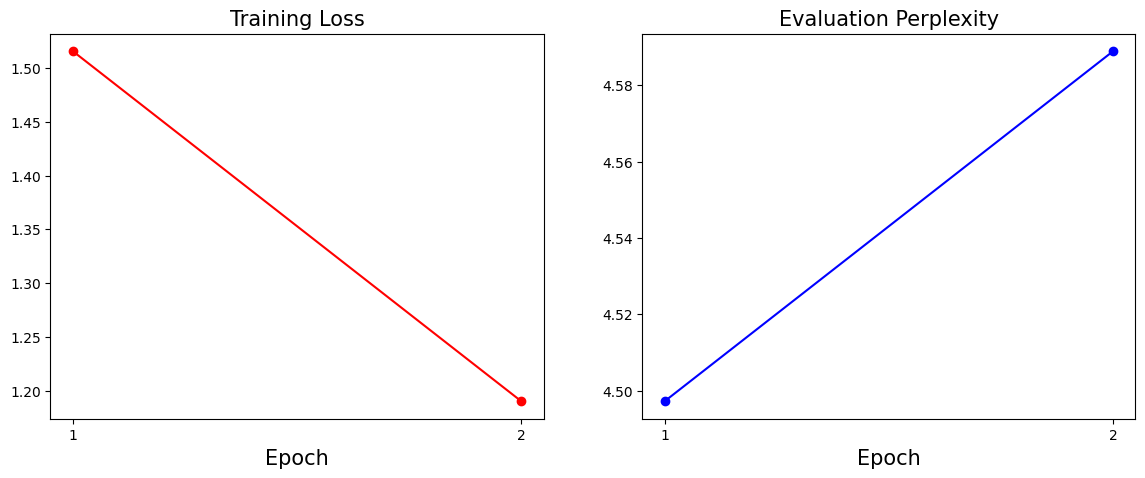

In [94]:
epochs = range(1, len(epoch_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, values, title, color in zip(axes, [epoch_losses, eval_perplexity],
                                    ['Training Loss', 'Evaluation Perplexity'], ['red', 'blue']):
    ax.plot(epochs, values, color=color, marker='o')
    ax.set_title(title, fontsize=15)
    ax.set_xlabel('Epoch', fontsize=15)
    ax.set_xticks(list(epochs))

plt.show()

In case we don't have enough time to train the model, this plot below is from another training run that didnt overfit:

<img align="center" style="max-width: 700px; height: auto" src="./assets/gpt_track.png">

#### 3.6. Text Generation

The training loop saved the trained weights to `gpt_shakespeare.pt`. To use them (e.g. in a fresh session, without retraining), build the model again and load the weights:

In [95]:
gpt_model = GPTLanguageModel(embed_dim=embed_dim, num_heads=num_heads, n_layer=n_layer, pos_len=pos_len).to(device)
gpt_model.load_state_dict(torch.load("gpt_shakespeare.pt", map_location=device))
gpt_model.eval()

GPTLanguageModel(
  (token_embedding_table): Embedding(65, 384)
  (position_embedding_table): Embedding(100, 384)
  (blocks): Sequential(
    (0): Block(
      (sa): MultiheadAttention(
        (query): Linear(in_features=384, out_features=384, bias=True)
        (key): Linear(in_features=384, out_features=384, bias=True)
        (value): Linear(in_features=384, out_features=384, bias=True)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (attn_dropout): Dropout(p=0.2, inplace=False)
        (proj_dropout): Dropout(p=0.2, inplace=False)
      )
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): ReLU()
          (2): Linear(in_features=1536, out_features=384, bias=True)
          (3): Dropout(p=0.2, inplace=False)
        )
      )
      (ln1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (ln2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    )
    

GPT generation:

In [96]:
prompt = "JULIET:\n I hate you, ROMEO.\n ROMEO:\n "
res = gpt_model.generate(prompt, char_to_int, int_to_char, device)
print(res)

JULIET:
 I hate you, ROMEO.
 ROMEO:
 should I call your children queen and you my father's
left me as prove as less as you! I us will
not be more strange more. These sides must I have:
neither does, even give me thy soul for place.

HENRY BOLINGBROKE:
I fear, my lord;
If they note come for this hour,
'Tis spotten out to take them too m


#### 3.7. Attention Visualization

We can look up the relation between the input and the output by plotting the attention maps.

In [97]:
prompt = "King: \n"
res, attn_list = gpt_model.generate(prompt, char_to_int, int_to_char, device, max_new_tokens=10, return_attention=True) # to better visualize the attention, we only generate 10 tokens

print(res)

King: 
How shall 


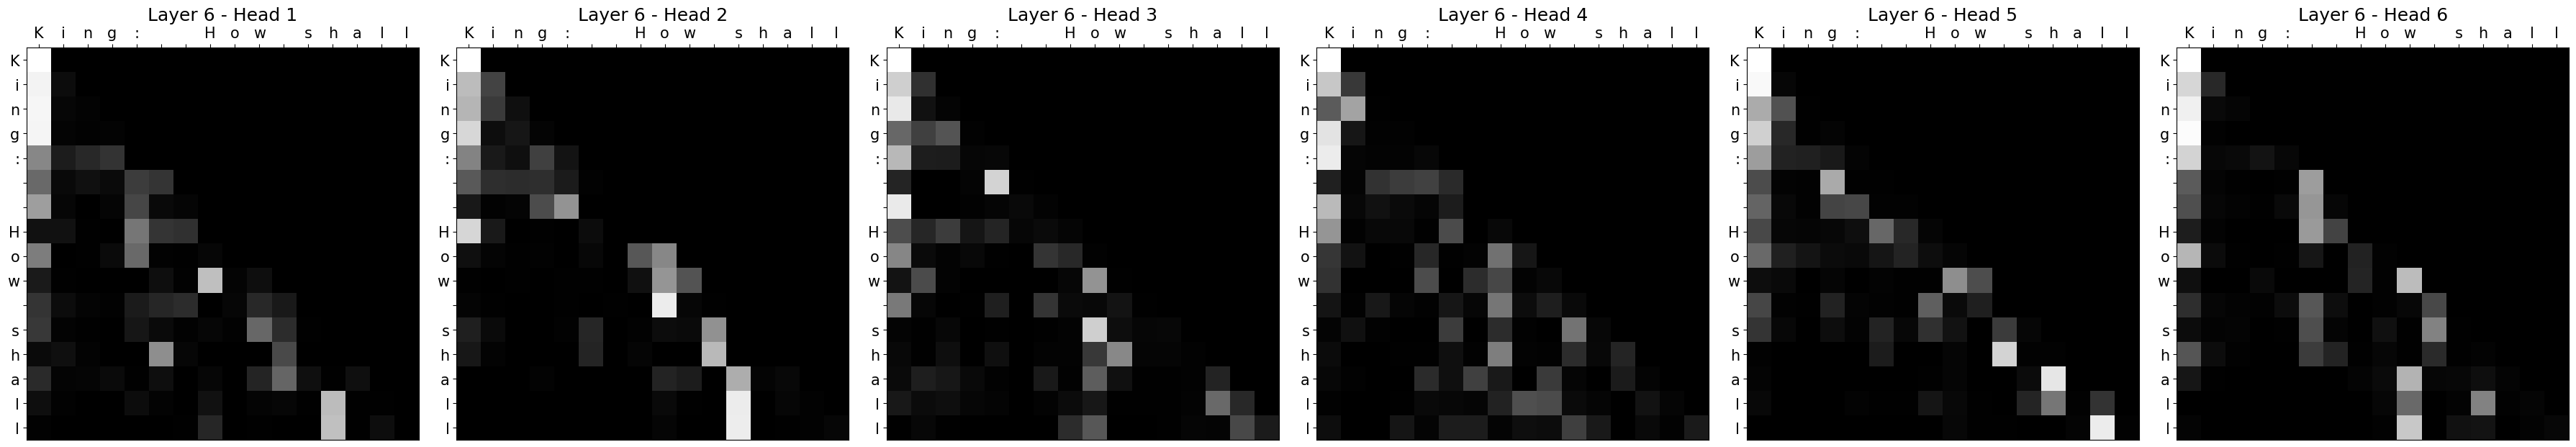

In [ ]:
layer_to_plot = 5   # pick one layer to visualize (0 = first layer, 5 = last layer)

attention = attn_list[layer_to_plot][0].cpu()  # first (only) batch element -> (heads, T, T)
tokens = list(res[:attention.shape[-1]])       # the T characters the model was looking at (queries = keys)

fig, axes = plt.subplots(1, num_heads, figsize=(6 * num_heads, 6))
for head, ax in enumerate(axes):
    ax.imshow(attention[head], cmap='gray')
    ax.set_title(f"Layer {layer_to_plot + 1} - Head {head + 1}", fontsize=18)
    ax.set_xticks(range(len(tokens)), tokens, fontsize=15)  # keys (attended to)
    ax.set_yticks(range(len(tokens)), tokens, fontsize=15)  # queries (attending)
    ax.xaxis.tick_top()

plt.tight_layout()
plt.show()